# Лабораторная работа 2. Классификация. Нейронные сети


**Тема:** классификация вина по качеству (Wine Quality).

## 1. Введение

**Цель работы:** изучить методы классификации из библиотеки Scikit-Learn, а также познакомиться с нейронными сетями на TensorFlow/Keras и инструментом визуализации обучения TensorBoard.

**Задачи:**
1. Выбрать и подготовить датасет, построить модели пятью методами: наивный Байес (GaussianNB, MultinomialNB, ComplementNB, BernoulliNB), дерево решений, линейный дискриминантный анализ (LDA), метод опорных векторов (SVM), метод k ближайших соседей (kNN).
2. Сравнить качество по метрикам Accuracy, Precision, Recall, F1-score, AUC-ROC.
3. Настроить гиперпараметры каждого метода и исследовать их влияние на качество.
4. Реализовать нейронную сеть на TensorFlow, исследовать влияние гиперпараметров, визуализировать обучение в TensorBoard.
5. Выполнить сравнительный анализ и сделать вывод о лучшем подходе.

Во всех экспериментах зафиксирован `SEED = 42`, поэтому результаты воспроизводимы.

## 2. Выбор и подготовка датасета

**Датасет:** *Wine Quality* (Cortez et al., 2009; UCI / Kaggle, файл `winequalityN.csv`) — физико-химические показатели португальских вин «Vinho Verde» (красных и белых) и экспертная оценка качества.

| Признак | Тип | Описание |
|---|---|---|
| `fixed acidity` | числовой | нелетучие кислоты (винная кислота), г/л |
| `volatile acidity` | числовой | летучие кислоты (уксусная кислота), г/л |
| `citric acid` | числовой | лимонная кислота, г/л |
| `residual sugar` | числовой | остаточный сахар, г/л |
| `chlorides` | числовой | хлориды (соль), г/л |
| `free sulfur dioxide` | числовой | свободный диоксид серы, мг/л |
| `total sulfur dioxide` | числовой | общий диоксид серы, мг/л |
| `density` | числовой | плотность, г/см³ |
| `pH` | числовой | кислотность (pH) |
| `sulphates` | числовой | сульфаты, г/л |
| `alcohol` | числовой | содержание спирта, % об. |
| `type` | категориальный | тип вина: `red` или `white` |
| `quality` | целое 3–9 | экспертная оценка качества |

**Постановка задачи классификации.** Оценка `quality` почти у всех вин равна 5–6, поэтому исходная задача с 7 классами несбалансирована и неудобна для метрик Precision/Recall/ROC-AUC. Решается **бинарная** задача: класс **1 — хорошее вино** (`quality ≥ 7`), класс **0** — остальные. Так метрики Precision, Recall, F1 и AUC-ROC определены однозначно, а задача отвечает на практический вопрос «будет ли вино высокого качества».



**Что делает ячейка.** Проверяет, какие библиотеки отсутствуют, и устанавливает только их (в Google Colab все они уже есть, на чистом компьютере установка занимает несколько минут из-за TensorFlow). Ничего не выводит, если всё установлено.

In [ ]:
import importlib.util, subprocess, sys

REQUIRED = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "sklearn": "scikit-learn", "tensorflow": "tensorflow"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Устанавливаются пакеты:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("Все необходимые пакеты уже установлены.")

**Что делает ячейка.** Подключает библиотеки: `pandas`/`numpy` — таблицы и массивы, `matplotlib`/`seaborn` — графики, из `sklearn` — разбиение выборки, кросс-валидацию и подбор гиперпараметров (`train_test_split`, `StratifiedKFold`, `GridSearchCV`), предобработку (`SimpleImputer`, `StandardScaler`, `MinMaxScaler`, `OneHotEncoder`, `ColumnTransformer`, `Pipeline`), пять семейств классификаторов и метрики. Здесь же задаются `SEED = 42` (воспроизводимость), имя файла, порог бинаризации цели (`quality ≥ 7`) и списки числовых и категориальных признаков. Ничего не выводит.

In [ ]:
import os, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve)

SEED = 42                       # фиксируем генератор случайных чисел
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

DATA_FILE = "winequalityN.csv"  # файл датасета (рядом с ноутбуком)
TARGET = "good"                 # бинарная цель: 1 - хорошее вино (quality >= 7)
QUALITY_THRESHOLD = 7
NUM_COLS = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
            "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]
CAT_COLS = ["type"]             # красное / белое

**Что делает ячейка.** Находит файл датасета (рядом с ноутбуком, в папке `data/` или `/content`; в Colab при отсутствии — предлагает загрузить), читает его и выводит первичную информацию: размер, типы столбцов, число пропусков, число полных дубликатов, распределение оценок качества и типов вина.

In [ ]:
def find_file(name):
    for p in (Path(name), Path("data") / name, Path("/content") / name):
        if p.exists():
            return p
    return None


if find_file(DATA_FILE) is None:      # в Colab предлагаем загрузить файл вручную
    try:
        from google.colab import files
        print("Загрузите файл", DATA_FILE)
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Положите файл {DATA_FILE} рядом с ноутбуком")

df_raw = pd.read_csv(find_file(DATA_FILE))
print("Размер таблицы:", df_raw.shape)
print("\nТипы столбцов:\n", df_raw.dtypes)
print("\nПропуски по столбцам:\n", df_raw.isna().sum()[df_raw.isna().sum() > 0])
print("\nПолных дубликатов строк:", int(df_raw.duplicated().sum()))
print("\nКоличество вин по оценке качества:\n", df_raw["quality"].value_counts().sort_index())
print("\nТип вина:\n", df_raw["type"].value_counts())
print("Таблица 1. Первые строки исходного датасета Wine Quality")
df_raw.head()

Размер таблицы: (6497, 13)

Типы столбцов:
 type                        str
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Пропуски по столбцам:
 fixed acidity       10
volatile acidity     8
citric acid          3
residual sugar       2
chlorides            2
pH                   9
sulphates            4
dtype: int64

Полных дубликатов строк: 1168

Количество вин по оценке качества:
 quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Тип вина:
 type
white    4898
red      1599
Name: count, dtype: int64


,type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,white,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,white,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,white,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,white,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


**Результат.**

- **Размер:** 6497 вин × 13 столбцов (11 физико-химических признаков, `type`, `quality`). Красных вин 1599, белых 4898.
- **Типы:** все признаки — `float64`, `quality` — целое, `type` — текст (нужно кодирование).
- **Пропуски:** всего 38 значений в 7 признаках (`fixed acidity` — 10, `volatile acidity` — 8, `citric acid` — 3, `residual sugar` — 2, `chlorides` — 2, `pH` — 9, `sulphates` — 4) — менее 0,1 % таблицы, поэтому строки не удаляются, а пропуски заполняются медианой.
- **Дубликаты:** 1168 полностью повторяющихся строк (18 % таблицы). Это важно: если копии одного вина попадут и в обучающую, и в тестовую выборки, оценка качества будет завышена (особенно у kNN и дерева, которые «запоминают» объекты). Дубликаты удаляются.
- **Оценки качества:** сильно сконцентрированы в 5–6 (77 % вин); оценок 3, 4 и 9 очень мало.

**Что делает ячейка.** Очищает данные и формирует цель: удаляет полные дубликаты, создаёт бинарный признак `good` (1, если `quality ≥ 7`), выводит доли классов и описательные статистики числовых признаков.

In [ ]:
n_before = len(df_raw)
df = df_raw.drop_duplicates().reset_index(drop=True)          # 1. удаляем полные дубликаты
df[TARGET] = (df["quality"] >= QUALITY_THRESHOLD).astype(int)   # 2. бинарная цель
print(f"Удалено дубликатов: {n_before - len(df)}; осталось {len(df)} вин")
print("\nДоли классов (1 - хорошее вино):\n", df[TARGET].value_counts(normalize=True).round(3))
print("Таблица 2. Описательные статистики числовых признаков (после удаления дубликатов)")
df[NUM_COLS].describe().T.round(3)

Удалено дубликатов: 1168; осталось 5329 вин

Доли классов (1 - хорошее вино):
 good
0    0.81
1    0.19
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
fixed acidity,5319.0,7.217,1.319,3.800,6.400,7.000,7.700,15.900
volatile acidity,5321.0,0.344,0.168,0.080,0.230,0.300,0.410,1.580
citric acid,5326.0,0.319,0.147,0.000,0.240,0.310,0.400,1.660
residual sugar,5327.0,5.054,4.504,0.600,1.800,2.700,7.500,65.800
chlorides,5327.0,0.057,0.037,0.009,0.038,0.047,0.066,0.611
free sulfur dioxide,5329.0,30.060,17.816,1.000,16.000,28.000,41.000,289.000
total sulfur dioxide,5329.0,114.189,56.781,6.000,75.000,116.000,154.000,440.000
density,5329.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,5320.0,3.224,0.160,2.720,3.110,3.210,3.330,4.010
sulphates,5325.0,0.533,0.150,0.220,0.430,0.510,0.600,2.000


**Результат.**

- После удаления дубликатов осталось **5329** вин.
- **Классы несбалансированы:** хороших вин (`good = 1`) 19.0 %, остальных 81.0 %, то есть примерно 1 : 4. Модель, которая всегда отвечает «обычное вино», получит accuracy ≈ 0.81, поэтому по accuracy модели сравнивать нельзя — основными будут F1, Recall и AUC-ROC, а разбиение будет **стратифицированным**.
- **Масштабы признаков сильно различаются:** `density` ≈ 1 (σ ≈ 0.003), `total sulfur dioxide` в среднем ≈ 114 (σ ≈ 57), `chlorides` ≈ 0.06. Нужна стандартизация.
- **Тяжёлые хвосты:** максимумы `residual sugar` (65.8 г/л при медиане 2.7), `free sulfur dioxide` (289 при медиане 28) и `chlorides` (0.61 при медиане 0.05) далеко от основной массы. Выбросы не удаляются: это реальные вина, а используемые методы (деревья, SVM с RBF-ядром, kNN после масштабирования) к ним не критичны.

**Что делает ячейка.** Строит обзорные графики: распределение оценок качества с раскраской по классу, распределение классов по типам вина и корреляцию каждого признака с целью; затем boxplot шести признаков по классам и корреляционную матрицу всех числовых признаков.

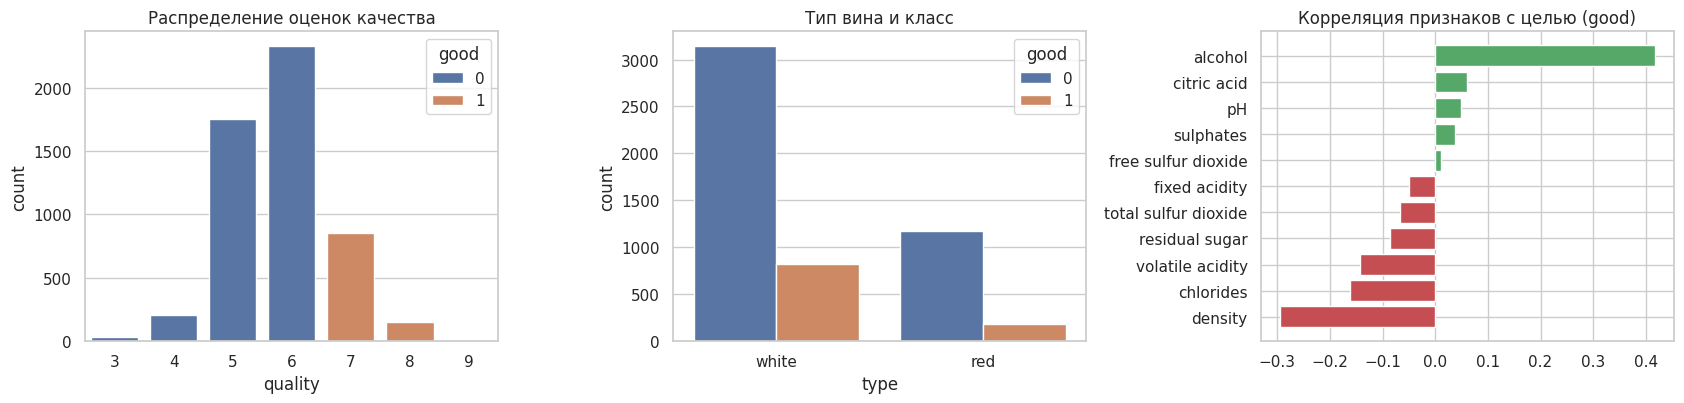

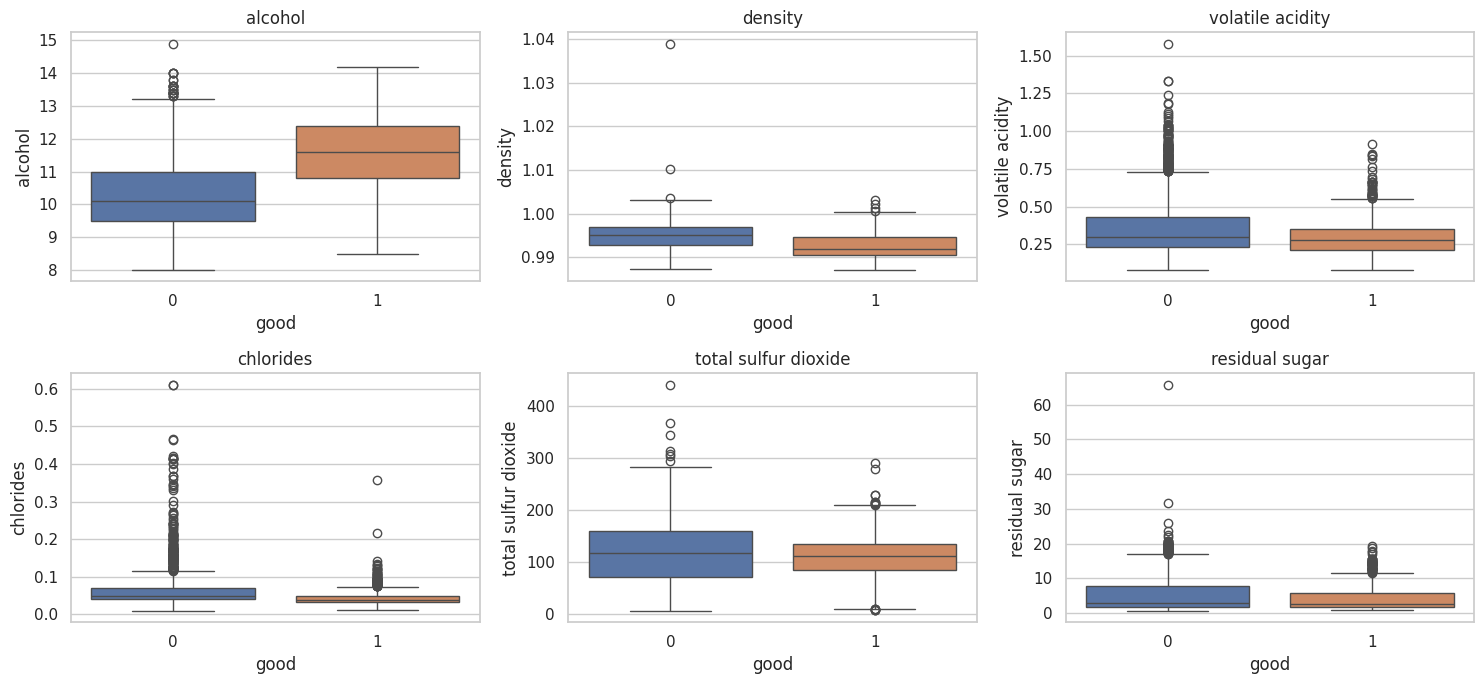

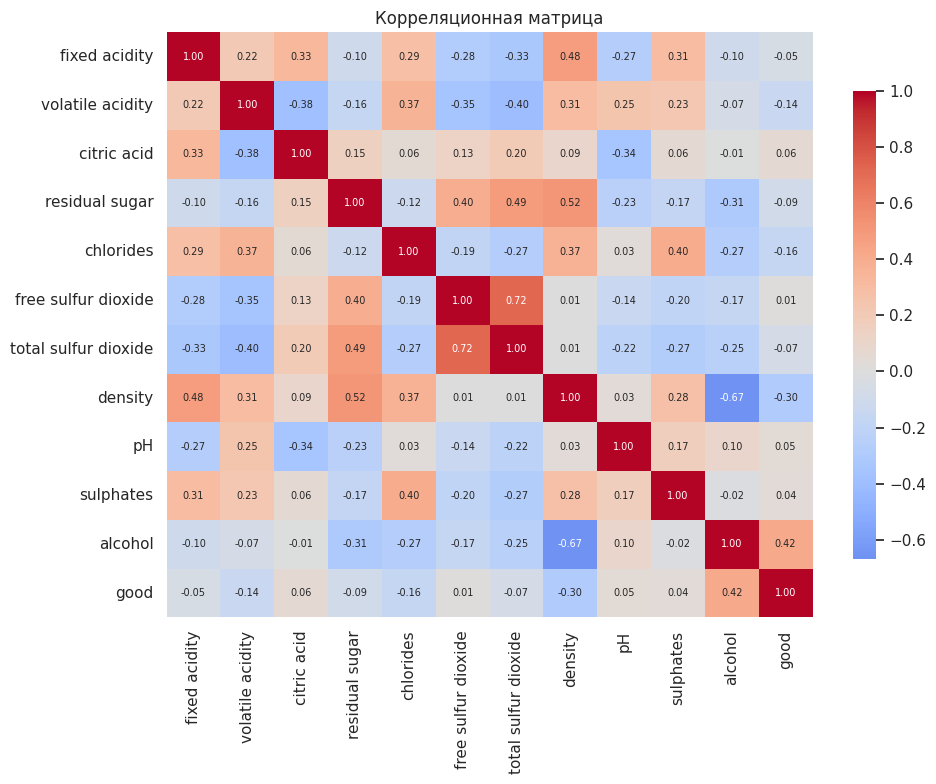

In [ ]:
print("Рисунок 1. Обзор целевой переменной: оценки качества, тип вина и корреляции признаков с good")
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.countplot(x="quality", hue=TARGET, data=df, ax=ax[0], palette=["#4C72B0", "#DD8452"])
ax[0].set_title("Распределение оценок качества"); ax[0].legend(title="good")
sns.countplot(x="type", hue=TARGET, data=df, ax=ax[1], palette=["#4C72B0", "#DD8452"])
ax[1].set_title("Тип вина и класс"); ax[1].legend(title="good")
corr_t = df[NUM_COLS + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()
ax[2].barh(corr_t.index, corr_t.values, color=np.where(corr_t.values > 0, "#55A868", "#C44E52"))
ax[2].set_title("Корреляция признаков с целью (good)")
plt.tight_layout(); plt.show()
print("Рис.1.Признаки распределение, тип вина и класса")
print("Рисунок 2. Boxplot ключевых признаков по классам (0 — обычное, 1 — хорошее вино)")
top = ["alcohol", "density", "volatile acidity", "chlorides", "total sulfur dioxide", "residual sugar"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(axes.ravel(), top):
    sns.boxplot(x=TARGET, y=c, data=df, ax=a, palette=["#4C72B0", "#DD8452"])
    a.set_title(c); a.set_xlabel("класс (good)")
plt.suptitle("Распределение признаков по классам качества", y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

print("Рисунок 3. Корреляционная матрица числовых признаков и целевой переменной")
plt.figure(figsize=(10, 8))
sns.heatmap(df[NUM_COLS + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            annot_kws={"size": 7}, cbar_kws={"shrink": .8})
plt.title("Корреляционная матрица"); plt.tight_layout(); plt.show()

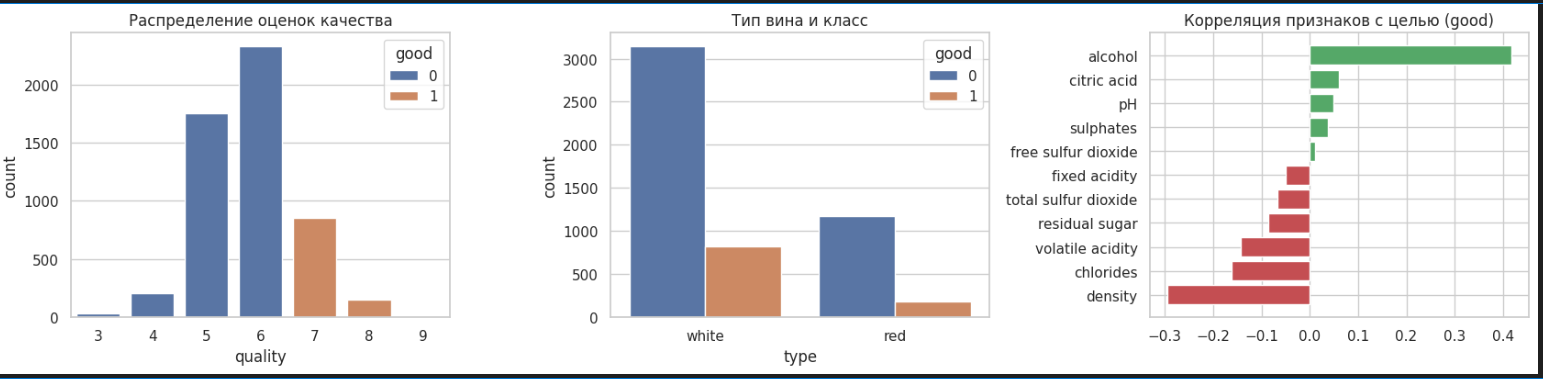
*Рис.1.Анализ каества вина*

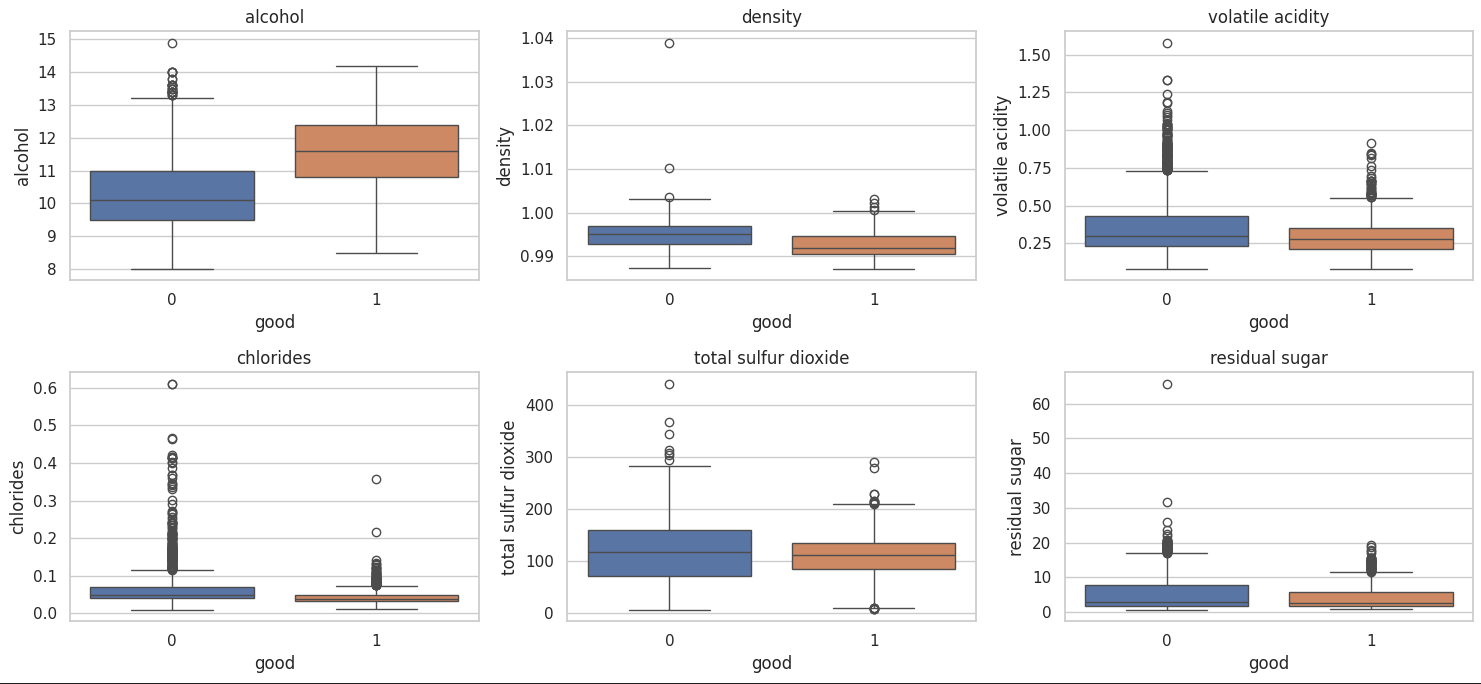
*Рис.2.Сравнение распределений признаков в зависимости от качества вина*

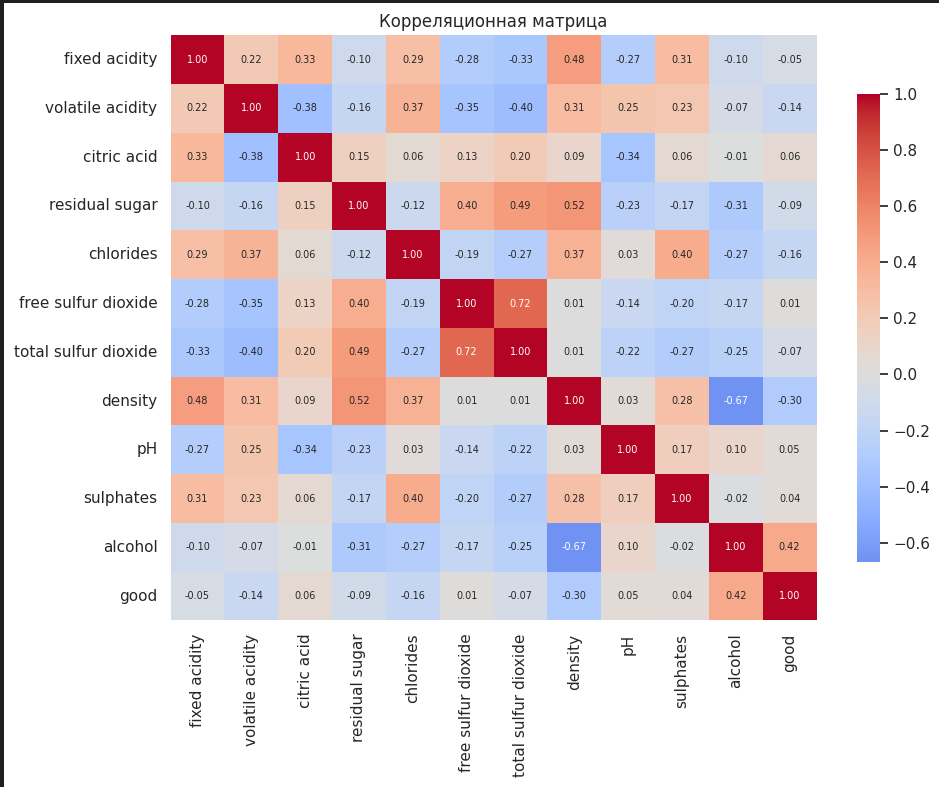

*Рис.3.Корреляционная матрица*

**Результат.**

- **Оценки:** хорошие вина — это оценки 7–9 (оценок 8 и 9 мало); граница классов проходит между самой частой оценкой 6 и оценкой 7.
- **Тип вина:** доля хороших вин среди белых 20.8 %, среди красных 13.5 % — белые вина получают высокую оценку заметно чаще, так что `type_white` несёт часть информации.
- **Связь с целью (корреляция Пирсона):** самый сильный признак — `alcohol` (r ≈ +0.42): чем крепче вино, тем чаще оно хорошее. Затем `density` (-0.30), `chlorides` (-0.16) и `volatile acidity` (-0.14). У остальных признаков |r| < 0,1. Линейная связь с целью в целом слабая, поэтому очень высокой точности ждать не стоит.
- **Boxplot:** у хороших вин выше медиана `alcohol` (11.6 против 10.1) и ниже `density`, `chlorides` и (чуть) `volatile acidity`; распределения классов заметно перекрываются — полностью разделить классы по одному признаку нельзя.
- **Корреляции между признаками:** самые сильные пары — `total sulfur dioxide` и `free sulfur dioxide` (+0.72), `density` и `alcohol` (-0.67), `residual sugar` и `density` (+0.52). Плотность вина определяется содержанием сахара и спирта, поэтому признаки частично дублируют друг друга. Для LDA и наивного Байеса (предполагающего независимость признаков) это нарушение предпосылок, для деревьев и kNN — нет.

### Предобработка

* **Дубликаты и цель:** удалены полные дубликаты, цель `good = (quality ≥ 7)`. Столбец `quality` в признаки не входит (иначе была бы утечка цели).
* **Пропуски:** числовые признаки — медиана, категориальные — самое частое значение (`most_frequent`).
* **Категориальный признак `type`:** One-Hot кодирование (`drop="if_binary"`: для двух категорий получается один столбец `type_white`).
* **Масштабирование:** два варианта признакового пространства:
  * `StandardScaler` (среднее 0, ст. откл. 1) — для GaussianNB, BernoulliNB, дерева, LDA, SVM, kNN и нейросети;
  * `MinMaxScaler` (диапазон [0, 1]) — для MultinomialNB и ComplementNB, которым нужны **неотрицательные** признаки.
* Все преобразования **обучаются только на обучающей выборке**, чтобы не было утечки данных.

## 3. Разбиение выборки

Стратифицированное разбиение 80 % / 20 % функцией `train_test_split` с фиксированным `random_state`. Подбор гиперпараметров выполняется кросс-валидацией **внутри обучающей выборки** (для нейросети — отдельная валидационная часть train). Тестовая выборка используется только для финальной оценки.

**Что делает ячейка.** Делит данные на train/test (`stratify=y` сохраняет долю хороших вин в обеих частях), собирает `ColumnTransformer` (числовые признаки: медиана + масштабирование; `type`: самое частое значение + One-Hot) и строит два варианта признаков — со `StandardScaler` и с `MinMaxScaler`. Преобразователи обучаются (`fit_transform`) только на train, к тесту применяется `transform`.

In [ ]:
X = df[NUM_COLS + CAT_COLS]
y = df[TARGET].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("train:", X_train.shape, " test:", X_test.shape)
print("доля класса 1: train=%.3f  test=%.3f" % (y_train.mean(), y_test.mean()))


def make_pre(scaler):
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", scaler)])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(drop="if_binary", sparse_output=False))])
    return ColumnTransformer([("num", num, NUM_COLS), ("cat", cat, CAT_COLS)])


pre_std, pre_mm = make_pre(StandardScaler()), make_pre(MinMaxScaler())
DATA = {                                     # данные считаются только по train
    "std": (pre_std.fit_transform(X_train), pre_std.transform(X_test)),
    "mm":  (pre_mm.fit_transform(X_train),  pre_mm.transform(X_test)),
}
FEATURE_NAMES = [n.split("__", 1)[1] for n in pre_std.get_feature_names_out()]
print("признаков после кодирования:", DATA["std"][0].shape[1], "->", FEATURE_NAMES[-2:])
print("пропусков после предобработки:", int(np.isnan(DATA["std"][0]).sum()))

train: (4263, 12)  test: (1066, 12)
доля класса 1: train=0.190  test=0.189
признаков после кодирования: 12 -> ['alcohol', 'type_white']
пропусков после предобработки: 0


**Результат.** Обучающая выборка — 4263 вин, тестовая — 1066, по 12 исходных признаков. Доля хороших вин одинакова (0.190 и 0.189) — стратификация сработала. После кодирования признаков остаётся 12 (11 числовых + `type_white`), пропусков не осталось. В тесте примерно 202 хороших вин — этого немного, поэтому метрики на тесте имеют заметный разброс (оценим его в разделе 7).

**Что делает ячейка.** Определяет вспомогательные функции, которые используются во всех экспериментах (ничего не выводит):

- `get_scores()` — непрерывная оценка класса 1 для ROC-кривой: вероятность (`predict_proba`) или значение решающей функции (`decision_function`, например у SVM);
- `metrics_from()` — считает Accuracy, Precision, Recall, F1 и AUC-ROC;
- `baseline()` — обучает модель с параметрами **по умолчанию** и запоминает метрики на тесте;
- `param_curve()` — исследует влияние **одного** гиперпараметра: для каждого значения выполняет 5-кратную стратифицированную кросс-валидацию на train и рисует AUC и F1 на обучении и на валидации. **Тест здесь не используется.** Расхождение кривых показывает переобучение;
- `run_grid()` — `GridSearchCV` по сетке параметров (5-кратная CV, критерий ROC-AUC), затем подбор **порога классификации** по F1 и оценка лучшей модели на тесте;
- `best_threshold()` — порог, максимизирующий F1 на внеблочных (out-of-fold) предсказаниях train.

**Зачем подбирать порог.** При дисбалансе 1 : 4 порог 0,5 почти всегда слишком высок: модель редко предсказывает редкий класс. ROC-AUC от порога не зависит, поэтому гиперпараметры подбираются по нему, а порог — отдельным шагом на обучающих данных. Так честно сравниваются F1, Precision и Recall.

In [ ]:
def get_scores(model, X):
    # непрерывная оценка класса 1 для ROC: вероятность или значение решающей функции
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def metrics_from(yte, pred, sc):
    return {"Accuracy": accuracy_score(yte, pred),
            "Precision": precision_score(yte, pred, zero_division=0),
            "Recall": recall_score(yte, pred),
            "F1": f1_score(yte, pred),
            "AUC-ROC": roc_auc_score(yte, sc)}


RESULTS_BASE, RESULTS_TUNED, RESULTS_TUNED_DEF, ROC_TUNED = {}, {}, {}, {}
BEST_PARAMS, THRESHOLDS, BEST_CV, TEST_SCORES = {}, {}, {}, {}
CV = StratifiedKFold(5, shuffle=True, random_state=SEED)


def baseline(name, model, data_key):
    # модель с параметрами по умолчанию, порог по умолчанию
    Xtr, Xte = DATA[data_key]
    model.fit(Xtr, y_train)
    RESULTS_BASE[name] = metrics_from(y_test, model.predict(Xte), get_scores(model, Xte))


def best_threshold(model, Xtr):
    # порог классификации, максимизирующий F1 на внеблочных (out-of-fold) оценках train
    method = "predict_proba" if hasattr(model, "predict_proba") else "decision_function"
    oof = cross_val_predict(model, Xtr, y_train, cv=CV, method=method)
    oof = oof[:, 1] if oof.ndim == 2 else oof
    cands = np.unique(np.quantile(oof, np.linspace(0.02, 0.98, 97)))
    f1s = [f1_score(y_train, oof >= t) for t in cands]
    return float(cands[int(np.argmax(f1s))])


def param_curve(estimator, data_key, param, values, title="", log_x=False):
    # Влияние одного параметра: AUC и F1 на train и на кросс-валидации (тест не используется)
    Xtr = DATA[data_key][0]
    rows = []
    for v in values:
        r = cross_validate(estimator.set_params(**{param: v}), Xtr, y_train, cv=CV,
                           scoring={"auc": "roc_auc", "f1": "f1"}, return_train_score=True)
        rows.append({param: v, "AUC_train": r["train_auc"].mean(), "AUC_cv": r["test_auc"].mean(),
                     "F1_train": r["train_f1"].mean(), "F1_cv": r["test_f1"].mean()})
    res = pd.DataFrame(rows)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    xs = res[param].astype(str) if not pd.api.types.is_numeric_dtype(res[param]) else res[param]
    for a, (c1, c2, t) in zip(ax, [("AUC_train", "AUC_cv", "AUC-ROC"), ("F1_train", "F1_cv", "F1-score")]):
        a.plot(xs, res[c1], "o-", label="train")
        a.plot(xs, res[c2], "s-", label="кросс-валидация")
        a.set_xlabel(param); a.set_title(f"{title} {t}"); a.legend()
        if log_x:
            a.set_xscale("log")
    fig.suptitle(f"Рисунок. Влияние параметра «{param}» ({title})" if title else f"Рисунок. Влияние параметра «{param}»", y=1.02, fontsize=11)
    plt.tight_layout(); plt.show()
    return res


def run_grid(name, estimator, grid, data_key):
    # 1) GridSearchCV по ROC-AUC (5-кратная стратифицированная CV на train)
    # 2) порог классификации подбирается по F1 на train (out-of-fold)
    # 3) оценка на тесте: при пороге по умолчанию и при подобранном пороге
    Xtr, Xte = DATA[data_key]
    gs = GridSearchCV(estimator, grid, scoring={"auc": "roc_auc", "f1": "f1"}, refit="auc",
                      cv=CV, n_jobs=-1).fit(Xtr, y_train)
    best = gs.best_estimator_
    sc = get_scores(best, Xte)
    thr = best_threshold(best, Xtr)
    RESULTS_TUNED_DEF[name] = metrics_from(y_test, best.predict(Xte), sc)
    RESULTS_TUNED[name] = metrics_from(y_test, sc >= thr, sc)
    BEST_PARAMS[name], THRESHOLDS[name], BEST_CV[name] = gs.best_params_, thr, gs.best_score_
    TEST_SCORES[name] = sc
    ROC_TUNED[name] = roc_curve(y_test, sc)[:2] + (RESULTS_TUNED[name]["AUC-ROC"],)
    print(f"{name}: лучшие параметры {gs.best_params_}, CV AUC = {gs.best_score_:.4f}, порог = {thr:.3f}")
    cvr = pd.DataFrame(gs.cv_results_)

    params = pd.DataFrame([{k: ("None" if v is None else v) for k, v in p.items()}
                           for p in cvr["params"]]).fillna("-")
    out = pd.concat([params, cvr[["mean_test_auc", "mean_test_f1"]]
                     .rename(columns={"mean_test_auc": "CV AUC", "mean_test_f1": "CV F1"})], axis=1)
    return out.sort_values("CV AUC", ascending=False).round(4).reset_index(drop=True)

## 4. Методы классификации

* **Наивный Байесовский классификатор** — применяет теорему Байеса в предположении условной независимости признаков при заданном классе: $P(c\mid x)\propto P(c)\prod_i P(x_i\mid c)$. Варианты различаются моделью $P(x_i\mid c)$: *GaussianNB* — нормальное распределение (непрерывные признаки); *MultinomialNB* — мультиномиальное (счётчики, неотрицательные признаки); *ComplementNB* — модификация Multinomial, устойчивая к дисбалансу классов (использует статистику «дополнения» класса); *BernoulliNB* — бинарные признаки. Ключевые параметры: `var_smoothing`, `alpha`, `norm`, `binarize`.
* **Дерево решений** — иерархия правил вида «признак ≤ порог», разбиения выбираются по критерию Gini или энтропии. Параметры: `max_depth`, `min_samples_leaf`, `criterion`, `class_weight`. Склонно к переобучению при большой глубине.
* **Линейный дискриминантный анализ (LDA)** — моделирует классы нормальными распределениями с общей ковариационной матрицей и строит линейную разделяющую поверхность. Параметры: `solver`, `shrinkage`.
* **Метод опорных векторов (SVM)** — строит разделяющую гиперплоскость с максимальным зазором; с ядрами (RBF, polynomial) — нелинейную границу. Параметры: `C`, `kernel`, `gamma`, `class_weight`.
* **k ближайших соседей (kNN)** — относит объект к классу, преобладающему среди $k$ ближайших обучающих объектов. Параметры: `n_neighbors`, `weights`, `p` (метрика Минковского).

Сначала каждый метод обучается с параметрами **по умолчанию** (baseline), затем настраивается.

**Что делает ячейка.** Обучает восемь моделей с параметрами по умолчанию и выводит их метрики на тесте. GaussianNB, BernoulliNB, дерево, LDA, SVM и kNN получают стандартизованные признаки, MultinomialNB и ComplementNB — нормированные в [0, 1]. Это точка отсчёта для оценки эффекта настройки.

In [ ]:
baseline("GaussianNB",   GaussianNB(),                              "std")
baseline("MultinomialNB", MultinomialNB(),                          "mm")
baseline("ComplementNB", ComplementNB(),                            "mm")
baseline("BernoulliNB",  BernoulliNB(),                             "std")
baseline("DecisionTree", DecisionTreeClassifier(random_state=SEED), "std")
baseline("LDA",          LinearDiscriminantAnalysis(),              "std")
baseline("SVM",          SVC(random_state=SEED),                    "std")
baseline("kNN",          KNeighborsClassifier(),                    "std")
print("Таблица 3. Метрики baseline-моделей на тестовой выборке (порог 0.5)")
pd.DataFrame(RESULTS_BASE).T.round(4)

,Accuracy,Precision,Recall,F1,AUC-ROC
GaussianNB,0.7345,0.3798,0.6337,0.4750,0.7499
MultinomialNB,0.8105,0.0000,0.0000,0.0000,0.7566
ComplementNB,0.6820,0.3396,0.7178,0.4610,0.7566
BernoulliNB,0.7392,0.3527,0.4505,0.3957,0.7196
DecisionTree,0.7683,0.3963,0.4257,0.4105,0.6371
LDA,0.8199,0.5379,0.3515,0.4251,0.8152
SVM,0.8415,0.6988,0.2871,0.4070,0.8108
kNN,0.8199,0.5347,0.3812,0.4451,0.7838


**Результат.**

- **Accuracy (0.68–0.84) почти ничего не говорит:** модель «всегда обычное вино» даёт 0.811. У MultinomialNB accuracy ровно 0.811, а Precision, Recall и F1 равны 0 — она вообще не предсказывает хорошие вина.
- **SVM** имеет лучшую accuracy (0.841) и Precision (0.70), но Recall всего 0.29: она осторожна и находит менее трети хороших вин. **ComplementNB**, наоборот, находит 72 % хороших вин, но с низкой Precision (0.34) — этот вариант создан для несбалансированных данных.
- **AUC-ROC:** лучшие — LDA (0.815) и SVM (0.811); худшее — **дерево решений (0.637)**: неограниченное дерево идеально запоминает обучающие данные и плохо обобщает. Его нужно настраивать в первую очередь.

## 5. Настройка гиперпараметров

Для каждого метода: (а) график влияния ключевого параметра на AUC и F1 для обучающих данных и кросс-валидации, (б) `GridSearchCV` (5-кратная стратифицированная CV, критерий ROC-AUC), (в) подбор порога по F1 и оценка итоговой модели на тесте. Параметры выбираются только по кросс-валидации на train; тест на выбор не влияет.

### 5.1 Наивные Байесовские классификаторы

**Что делает ячейка.** Исследует **GaussianNB**. Единственный параметр — `var_smoothing`: доля максимальной дисперсии признаков, прибавляемая ко всем дисперсиям для устойчивости вычислений. Перебираются 14 значений от 10⁻¹¹ до 100 (логарифмическая шкала): строятся кривые AUC и F1 для train и CV, затем `GridSearchCV` выбирает лучшее значение.

GaussianNB: лучшие параметры {'var_smoothing': np.float64(10.0)}, CV AUC = 0.7962, порог = 0.215


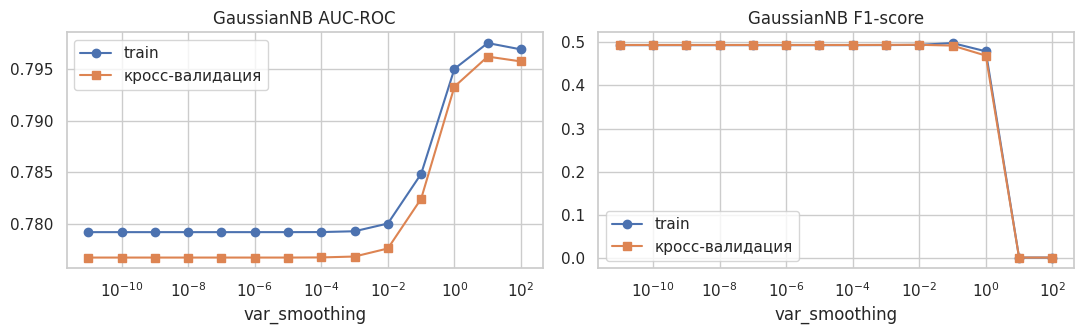

,var_smoothing,CV AUC,CV F1
0,10.00,0.7962,0.0000
1,100.00,0.7958,0.0000
2,1.00,0.7933,0.4695
3,0.10,0.7824,0.4927
4,0.01,0.7776,0.4946


In [ ]:
r = param_curve(GaussianNB(), "std", "var_smoothing", np.logspace(-11, 2, 14), "GaussianNB", log_x=True)
print("Таблица 4. GridSearchCV: GaussianNB (топ по CV AUC)")
run_grid("GaussianNB", GaussianNB(), {"var_smoothing": np.logspace(-11, 2, 14)}, "std").head()

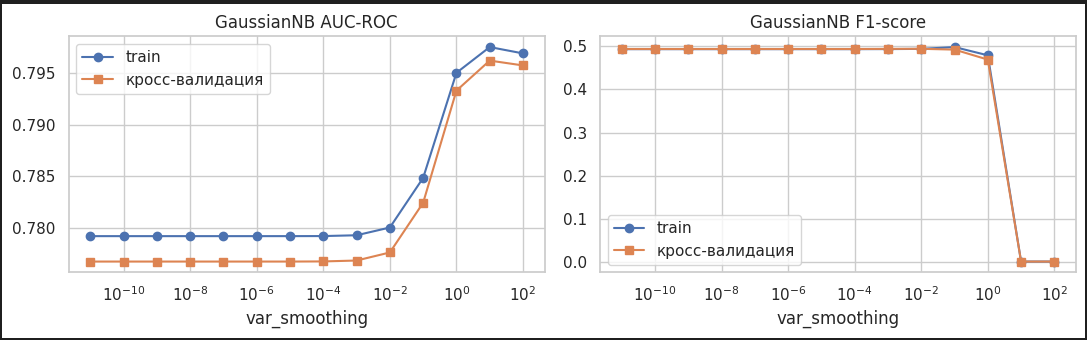

*Рис.4.Подбор гиперпараметра var_smoothing для наивного байесовского классификатора*

**Результат.**

- При `var_smoothing` ≤ 10⁻³ качество не меняется (AUC на CV ≈ 0.777): добавка к дисперсиям ничтожна.
- При значениях 0,1–10 AUC растёт (0.782 → 0.793 → 0.796): сглаживание делает оценки дисперсий устойчивее, а вероятности класса менее экстремальными, что улучшает ранжирование объектов.
- **F1 при пороге по умолчанию** при этом падает: 0.493 при 0,1, 0.469 при 1 и **0 при ≥ 10** — модель перестаёт предсказывать класс 1 с вероятностью выше 0,5. Ранжирование (AUC) лучше, а решение при пороге 0,5 хуже — наглядный пример, зачем нужен отдельный подбор порога.
- Кривые train и CV почти совпадают — переобучения нет (у наивного Байеса мало параметров).
- `GridSearchCV` выбрал `var_smoothing = 10` (CV AUC 0.7962). На тесте AUC вырос с 0.750 до 0.765; при пороге по умолчанию F1 = 0.000, а при подобранном пороге 0.215 — 0.472.

**Что делает ячейка.** Исследует **MultinomialNB** на признаках в [0, 1]. Параметр `alpha` — сглаживание Лапласа: добавка к частотам, защищающая от нулевых вероятностей. Перебираются значения от 0,001 до 100.

MultinomialNB: лучшие параметры {'alpha': 30}, CV AUC = 0.8049, порог = 0.195


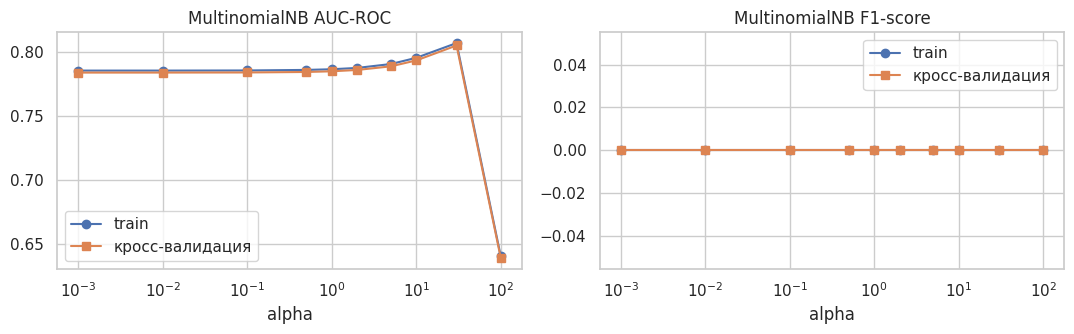

,alpha,CV AUC,CV F1
0,30.0,0.8049,0.0
1,10.0,0.7933,0.0
2,5.0,0.7887,0.0
3,2.0,0.7859,0.0
4,1.0,0.7848,0.0


In [ ]:
alphas = [1e-3, 1e-2, 0.1, 0.5, 1, 2, 5, 10, 30, 100]
r = param_curve(MultinomialNB(), "mm", "alpha", alphas, "MultinomialNB", log_x=True)
print("Таблица 5. GridSearchCV: MultinomialNB (топ по CV AUC)")
run_grid("MultinomialNB", MultinomialNB(), {"alpha": alphas}, "mm").head()

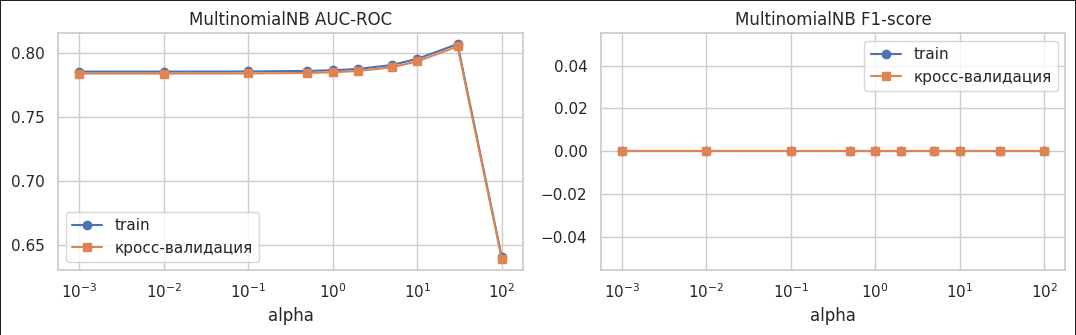

*Рис.5. Зависимость метрик качества модели MultinomialNB от параметра alpha*

**Результат.**

- **AUC** почти не зависит от `alpha` при малых значениях (0.784) и растёт с 0.785 при `alpha = 1` до 0.805 при 30. При `alpha = 100` он **резко падает до 0.639**: добавка 100 к частотам признаков, лежащих в диапазоне [0, 1], полностью «заглушает» данные.
- **F1 при пороге по умолчанию равен 0 при всех `alpha`**: модель ни разу не оценивает вероятность хорошего вина выше 0,5 — она «всегда отвечает обычное вино» (accuracy 0.811, как у мажоритарного класса).
- MultinomialNB рассчитан на счётчики (например, частоты слов), а здесь признаки — непрерывные величины, искусственно приведённые к [0, 1]; поэтому модель подходит плохо.
- Лучшее по CV: `alpha = 30` (CV AUC 0.8049), тестовый AUC 0.784. После подбора порога (0.195) F1 на тесте = 0.489.

**Что делает ячейка.** Исследует **ComplementNB** — вариант MultinomialNB, который оценивает параметры по «дополнению» класса (всем объектам других классов) и потому устойчивее к дисбалансу. Перебираются `alpha` и `norm` (нормализация весов признаков).

ComplementNB: лучшие параметры {'alpha': 30, 'norm': True}, CV AUC = 0.8109, порог = 0.501


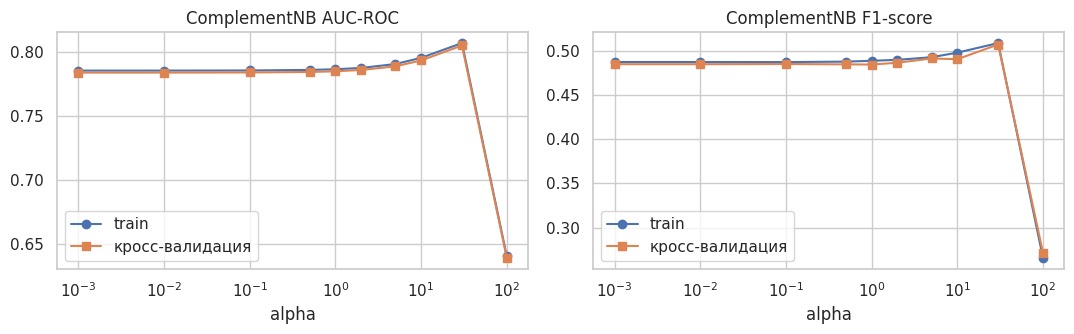

,alpha,norm,CV AUC,CV F1
0,30.0,True,0.8109,0.4015
1,30.0,False,0.8049,0.5072
2,10.0,True,0.8004,0.3387
3,5.0,True,0.7956,0.3329
4,10.0,False,0.7933,0.4906


In [ ]:
r = param_curve(ComplementNB(), "mm", "alpha", alphas, "ComplementNB", log_x=True)
print("Таблица 6. GridSearchCV: ComplementNB (топ по CV AUC)")
run_grid("ComplementNB", ComplementNB(), {"alpha": alphas, "norm": [False, True]}, "mm").head()

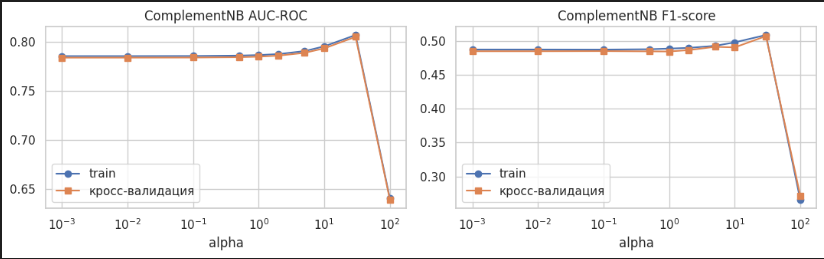

*Рис.6. Оценка модели ComplementNB (AUC-ROC и F1-score)*

**Результат.**

- Кривая AUC в зависимости от `alpha` такая же, как у MultinomialNB (0.785 при 1, 0.805 при 30, 0.639 при 100): обе модели ранжируют объекты одинаково, различие только в положении порога.
- **F1 при пороге по умолчанию не нулевой** (0.485 при `alpha = 1`, 0.507 при 30), в отличие от MultinomialNB: ComplementNB не смещается к большему классу — ради этого он и создан. При `alpha = 100` F1 падает до 0.272.
- Лучшие параметры: `alpha = 30, norm = True` (CV AUC 0.8109), тестовый AUC 0.792. Но `norm = True` при пороге по умолчанию **ухудшает** F1: при пороге 0,5 модель почти всех объявляет хорошими (Recall 0.980, Precision 0.223, accuracy 0.350). Подбор порога (0.501) возвращает F1 на уровень 0.491.

**Что делает ячейка.** Исследует **BernoulliNB**, который работает с бинарными признаками. Параметр `binarize` — порог, выше которого стандартизованный признак считается равным 1, ниже — 0. Также перебирается сглаживание `alpha`.

BernoulliNB: лучшие параметры {'alpha': 20, 'binarize': 0.25}, CV AUC = 0.7749, порог = 0.300


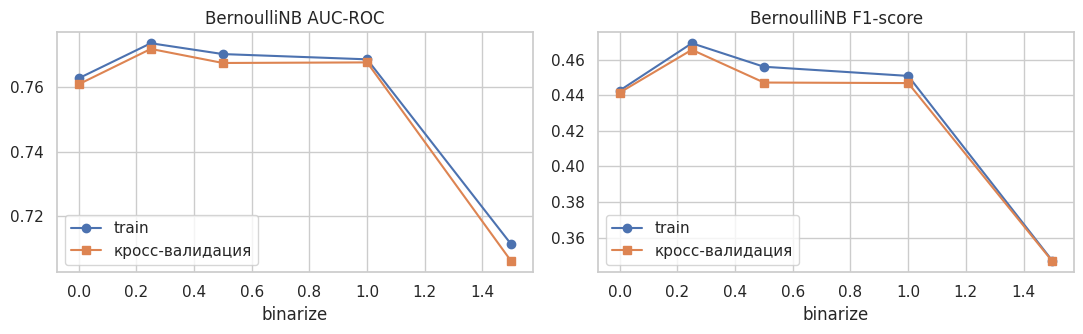

,alpha,binarize,CV AUC,CV F1
0,20.0,0.25,0.7749,0.4572
1,20.0,0.50,0.7731,0.4515
2,5.0,0.25,0.7726,0.4628
3,1.0,0.25,0.7718,0.4656
4,0.1,0.25,0.7714,0.4656


In [ ]:
r = param_curve(BernoulliNB(), "std", "binarize", [0.0, 0.25, 0.5, 1.0, 1.5], "BernoulliNB")
print("Таблица 7. GridSearchCV: BernoulliNB (топ по CV AUC)")
run_grid("BernoulliNB", BernoulliNB(), {"binarize": [0.0, 0.25, 0.5, 1.0], "alpha": [0.1, 1, 5, 20]}, "std").head()

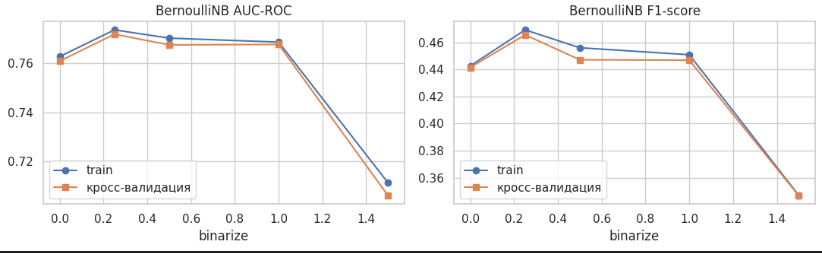

*Рис.7.Оценка модели BernoulliNB (AUC-ROC и F1-score)*

**Результат.**

- Порог бинаризации заметно влияет на качество: лучший — `binarize = 0,25` (AUC на CV 0.772). При 1,5 качество резко падает (AUC 0.706, F1 0.347): у стандартизованных признаков значения выше 1,5 σ встречаются редко, почти все признаки обращаются в нули и информация теряется.
- Бинаризация вообще отбрасывает большую часть информации о величине признаков, поэтому BernoulliNB — **самый слабый из наивных байесовских вариантов** (тестовый AUC 0.749).
- Лучшие параметры: `binarize = 0.25, alpha = 20` (CV AUC 0.7749); `alpha` влияет на результат мало.

### 5.2 Дерево решений

**Что делает ячейка.** Исследует **дерево решений**: влияние максимальной глубины `max_depth` (1…20 и без ограничения) и минимального числа объектов в листе `min_samples_leaf` (1…100), затем `GridSearchCV` по глубине, размеру листа, критерию разбиения (Gini или энтропия) и `class_weight` (веса классов; `balanced` придаёт больший вес редкому классу).

DecisionTree: лучшие параметры {'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 50}, CV AUC = 0.8111, порог = 0.574


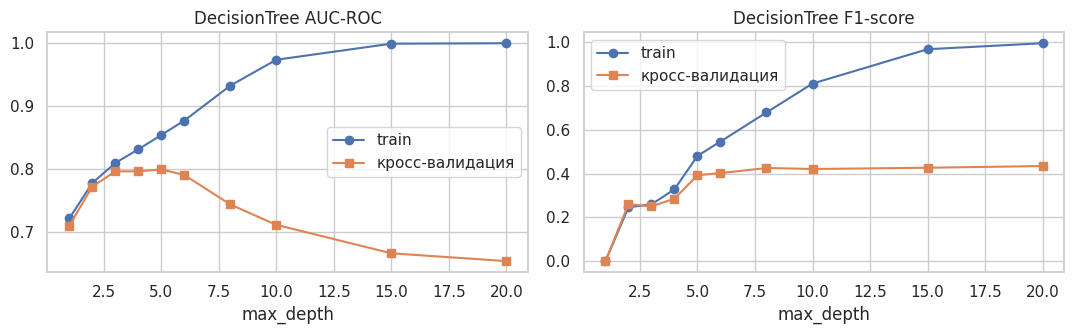

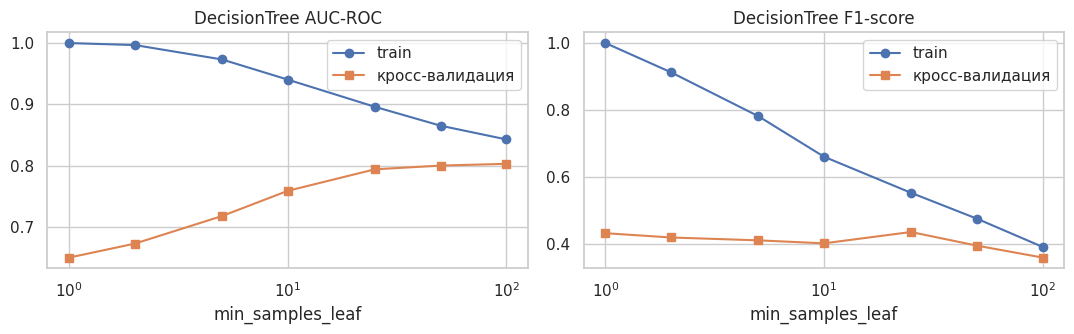

,class_weight,criterion,max_depth,min_samples_leaf,CV AUC,CV F1
0,balanced,entropy,12,50,0.8111,0.5135
1,balanced,entropy,None,50,0.8111,0.5135
2,balanced,gini,8,50,0.8111,0.5184
3,balanced,gini,12,50,0.8104,0.5175
4,balanced,gini,None,50,0.8104,0.5175
5,balanced,entropy,8,50,0.8103,0.5148
6,balanced,gini,5,50,0.8087,0.5165
7,balanced,gini,5,25,0.8086,0.5130


In [ ]:
r = param_curve(DecisionTreeClassifier(random_state=SEED), "std", "max_depth",
                [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, None], "DecisionTree")
r = param_curve(DecisionTreeClassifier(random_state=SEED), "std", "min_samples_leaf",
                [1, 2, 5, 10, 25, 50, 100], "DecisionTree", log_x=True)
print("Таблица 8. GridSearchCV: DecisionTree (топ по CV AUC)")
run_grid("DecisionTree", DecisionTreeClassifier(random_state=SEED),
         {"max_depth": [3, 5, 8, 12, None], "min_samples_leaf": [5, 10, 25, 50, 100],
          "criterion": ["gini", "entropy"], "class_weight": [None, "balanced"]}, "std").head(8)

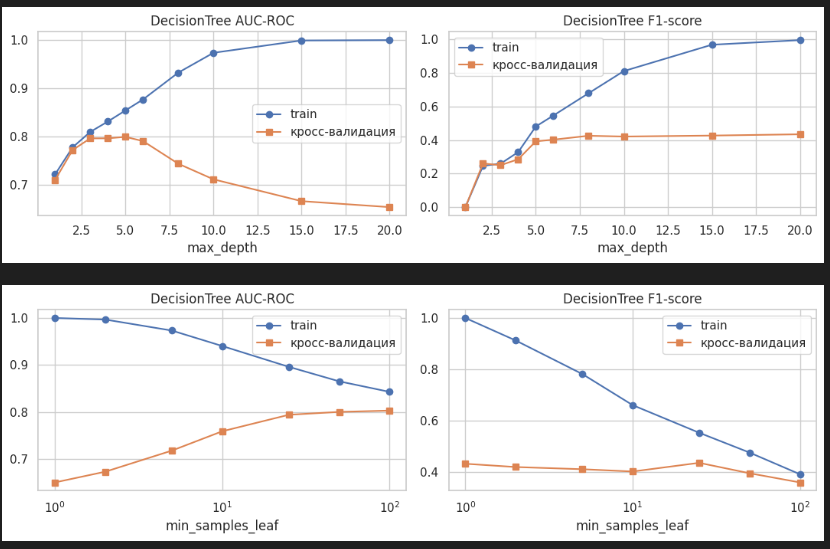

*Рис.8.Валидационные кривые DecisionTree: зависимость от max_depth и min_samples_leaf*

**Результат — классическая картина переобучения.**

- **Глубина.** При `max_depth = 1` F1 = 0: дерево из одного вопроса нигде не оценивает вероятность класса 1 выше 0,5. С ростом глубины метрики на train растут почти до идеальных (AUC 1.000, F1 0.997 при глубине 20), а AUC на кросс-валидации достигает максимума **0.800 при глубине 5** и дальше **падает** до 0.650 у дерева без ограничения: глубокое дерево запоминает шум обучающей выборки.
- **Размер листа.** При `min_samples_leaf = 1` дерево идеально описывает train (AUC 1.000), но на кросс-валидации AUC всего 0.650. Увеличение листа до 100 сближает кривые: AUC на train падает до 0.843, а на валидации растёт до 0.803 — это регуляризация. F1 на валидации от размера листа почти не зависит (≈ 0,36–0,44).
- **GridSearchCV:** лучшее — `{'class_weight': 'balanced', 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 50}`, CV AUC 0.8111. Ограничение сложности подняло тестовый AUC с 0.637 до **0.789** — самый большой прирост среди всех методов. Лучшее дерево использует `class_weight = "balanced"` (во всех восьми лучших вариантах таблицы веса сбалансированы); при пороге по умолчанию F1 на тесте вырос с 0.411 до 0.488 — вклад дают и ограничение глубины, и веса классов.

### 5.3 Линейный дискриминантный анализ

**Что делает ячейка.** Исследует **LDA**. Параметр `shrinkage` (сжатие) смешивает оценку ковариационной матрицы с диагональной: 0 — без сжатия, 1 — полностью диагональная матрица (признаки считаются некоррелированными). Сжатие работает только с решателями `lsqr` и `eigen`. Затем `GridSearchCV` сравнивает решатели `svd`, `lsqr`, `eigen` и разные значения сжатия.

LDA: лучшие параметры {'solver': 'svd'}, CV AUC = 0.8276, порог = 0.205


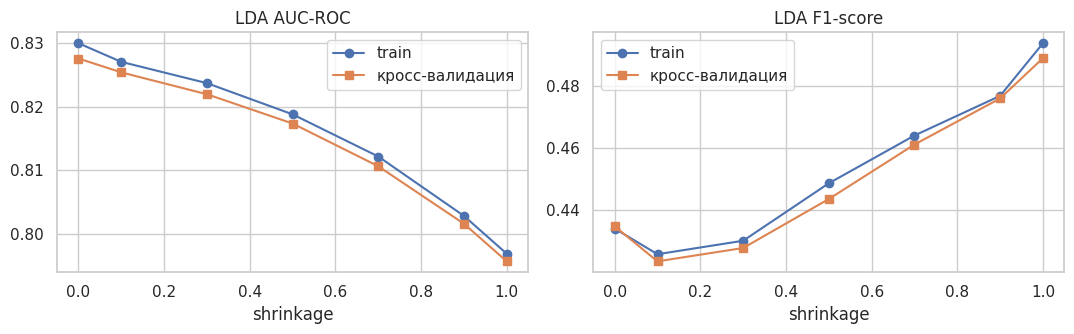

,solver,shrinkage,CV AUC,CV F1
0,svd,-,0.8276,0.4337
1,lsqr,None,0.8276,0.4349
2,eigen,None,0.8276,0.4349
3,lsqr,auto,0.8272,0.4335
4,eigen,auto,0.8272,0.4335
5,lsqr,0.1,0.8254,0.4236
6,eigen,0.1,0.8254,0.4236
7,lsqr,0.5,0.8173,0.4437


In [ ]:
r = param_curve(LinearDiscriminantAnalysis(solver="lsqr"), "std", "shrinkage", [0.0, 0.1, 0.3, 0.5, 0.7, 0.9, 1.0], "LDA")
print("Таблица 9. GridSearchCV: LDA (топ по CV AUC)")
run_grid("LDA", LinearDiscriminantAnalysis(),
         [{"solver": ["svd"]}, {"solver": ["lsqr", "eigen"], "shrinkage": [None, "auto", 0.1, 0.5, 0.9]}], "std").head(8)

**Результат.**

- AUC на кросс-валидации монотонно **падает** с ростом сжатия: 0.828 без сжатия → 0.817 при 0,5 → 0.796 при полном сжатии. Сжатие полезно, когда объектов мало относительно числа признаков; здесь 4263 объектов на 12 признаков, ковариационная матрица и так оценивается точно, а сжатие лишь вносит смещение (и игнорирует реальные корреляции между признаками — например, плотность и спирт).
- F1 при пороге по умолчанию, наоборот, немного растёт с ростом сжатия (0.435 → 0.489) — это не улучшение разделения, а сдвиг вероятностей в сторону редкого класса; AUC при этом хуже.
- Train и CV идут параллельно, разрыв минимален — переобучения нет.
- Лучший вариант — решатель `svd` без сжатия (CV AUC 0.8276); `lsqr` и `eigen` без сжатия дают то же самое, `auto` — практически то же. **Настройка LDA не нужна:** параметры по умолчанию оптимальны (тестовый AUC 0.815 до и после). Подбор порога (0.205) поднимает F1 с 0.425 до 0.518.

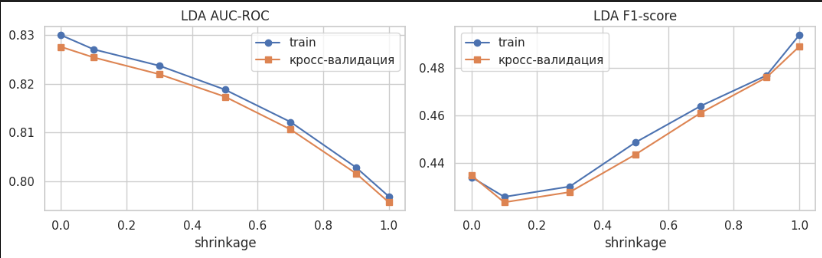

*Рис.9.Зависимость метрик качества модели LDA от параметра shrinkage*

### 5.4 Метод опорных векторов

Время обучения SVM растёт примерно как $O(n^2)$–$O(n^3)$ от числа объектов; на наших 4263 объектах (после удаления дубликатов) оно приемлемо, поэтому SVM обучается на **полной** обучающей выборке.

**Что делает ячейка.** Исследует **SVM**: влияние параметра регуляризации `C`, параметра ядра `gamma` (радиус влияния одного объекта для RBF-ядра) и типа ядра (linear, poly, rbf, sigmoid), затем `GridSearchCV` по `C`, `gamma` и `class_weight` для RBF-ядра. Ячейка выполняется дольше остальных (десятки секунд — минуты).

SVM: лучшие параметры {'C': 1, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}, CV AUC = 0.8476, порог = 0.419


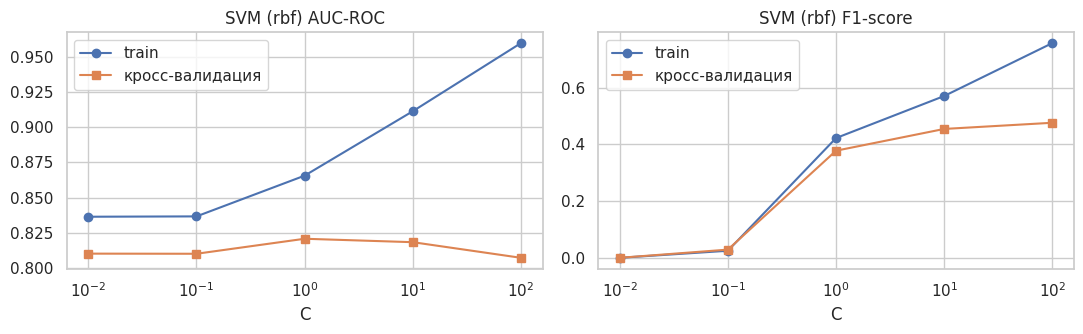

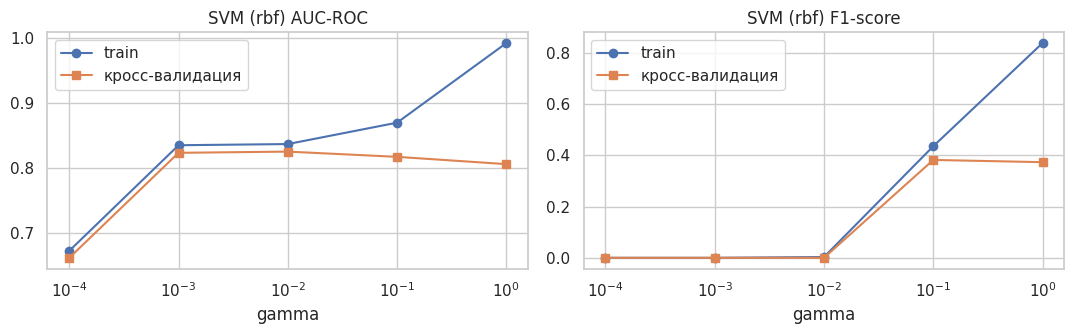

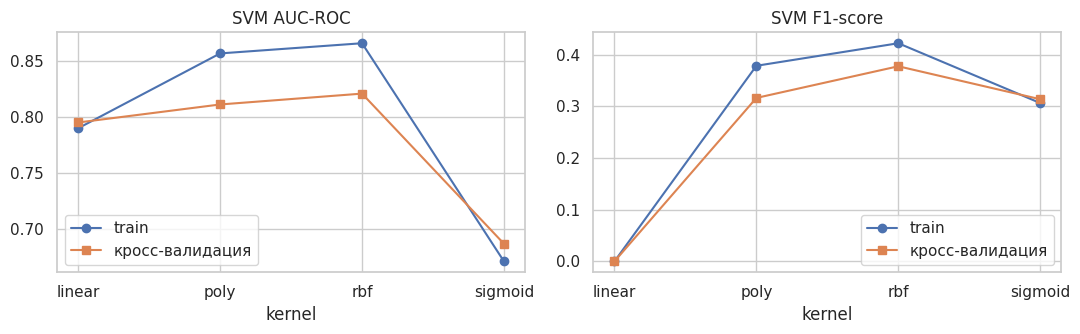

,C,class_weight,gamma,kernel,CV AUC,CV F1
0,1.0,balanced,scale,rbf,0.8476,0.5440
1,1.0,balanced,0.1,rbf,0.8467,0.5474
2,100.0,balanced,0.01,rbf,0.8453,0.5431
3,10.0,balanced,0.01,rbf,0.8448,0.5401
4,10.0,balanced,scale,rbf,0.8409,0.5532
5,10.0,balanced,0.1,rbf,0.8390,0.5572
6,0.1,balanced,scale,rbf,0.8378,0.5399
7,0.1,balanced,0.1,rbf,0.8376,0.5387


In [ ]:
r = param_curve(SVC(kernel="rbf", random_state=SEED), "std", "C", [0.01, 0.1, 1, 10, 100], "SVM (rbf)", log_x=True)
r = param_curve(SVC(kernel="rbf", C=1, random_state=SEED), "std", "gamma", [1e-4, 1e-3, 1e-2, 0.1, 1], "SVM (rbf)", log_x=True)
r = param_curve(SVC(C=1, random_state=SEED), "std", "kernel", ["linear", "poly", "rbf", "sigmoid"], "SVM")
print("Таблица 10. GridSearchCV: SVM (топ по CV AUC)")
run_grid("SVM", SVC(random_state=SEED),
         {"C": [0.1, 1, 10, 100], "gamma": ["scale", 0.01, 0.1], "kernel": ["rbf"],
          "class_weight": [None, "balanced"]}, "std").head(8)

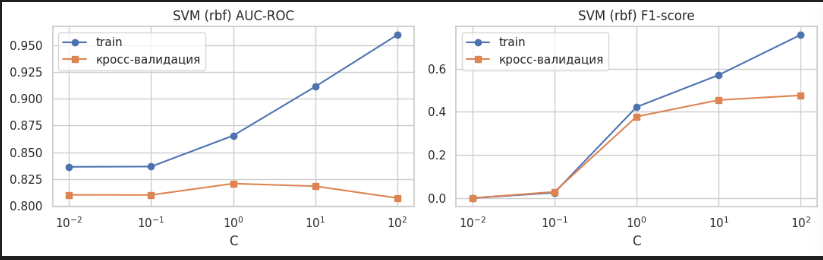

*Рис.10.Оценка модели SVM (AUC-ROC и F1-score)*

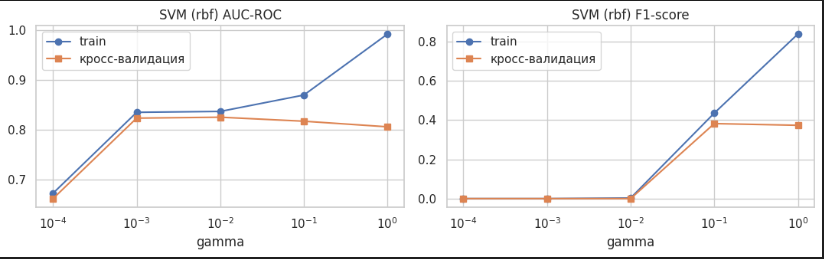

*Рис.11.Подбор гиперпараметров SVM: kernel, C и gamma*

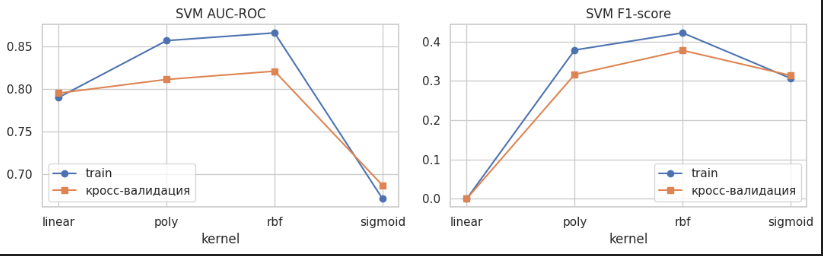

*Рис.12.Настройка SVM: зависимость метрик от kernel, C и gamma*

**Результат.**

- **Параметр C.** При C ≤ 0,1 F1 ≈ 0 — модель настолько регуляризована, что почти всех относит к обычным винам. AUC на кросс-валидации максимален при **C = 1** (0.821), а AUC на train растёт до 0.960 при C = 100, тогда как на валидации падает до 0.807 — переобучение.
- **Параметр gamma.** При gamma = 10⁻⁴ модель недообучена (AUC 0.663); лучшее значение — 10⁻²–10⁻³ (AUC 0.826). При gamma = 1 модель запоминает обучающую выборку (AUC на train 0.992), а на валидации AUC 0.806.
- **Ядро.** По AUC на CV: rbf (0.821) > poly (0.811) > linear (0.795) > sigmoid (0.687). Нелинейность помогает, но умеренно: RBF-ядро лучше линейного всего на 0.026 AUC. Sigmoid-ядро плохо подходит для этих признаков (на train оно даже хуже линейного). Нулевой F1 у линейного ядра (0.000) связан с порогом по умолчанию, а не с отсутствием информации в данных.
- **GridSearchCV:** лучшее — `{'C': 1, 'class_weight': 'balanced', 'gamma': 'scale', 'kernel': 'rbf'}`, CV AUC **0.8476**. Тестовый AUC вырос с 0.811 до 0.836. `class_weight = "balanced"` стоит во всех восьми лучших вариантах таблицы: утяжеление редкого класса улучшает и ранжирование, и F1 (при пороге по умолчанию F1 на тесте 0.407 → 0.532).

### 5.5 Метод k ближайших соседей

**Что делает ячейка.** Исследует **kNN**: влияние числа соседей `n_neighbors` (1…201), параметра `p` метрики Минковского (1 — манхэттенское расстояние, 2 — евклидово, 3 — Минковского 3-го порядка), затем `GridSearchCV` по числу соседей, весам (`uniform` — все соседи равны, `distance` — ближние важнее) и метрике.

kNN: лучшие параметры {'n_neighbors': 51, 'p': 1, 'weights': 'distance'}, CV AUC = 0.8493, порог = 0.281


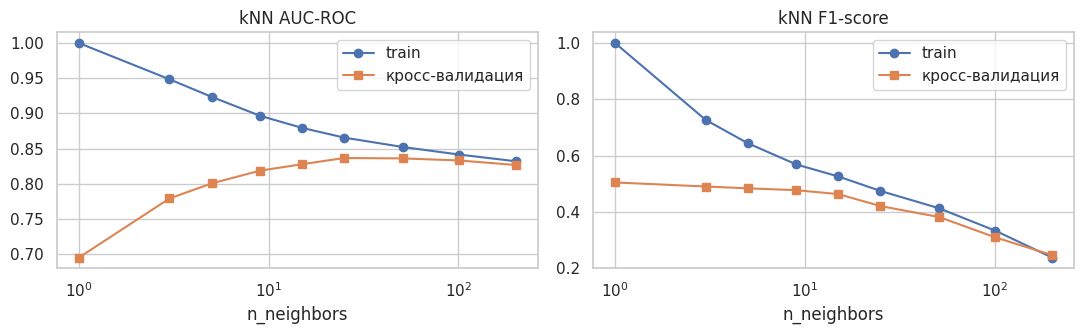

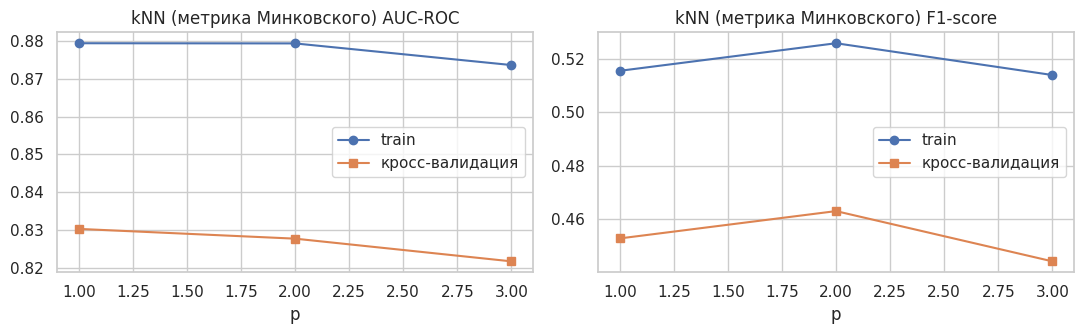

,n_neighbors,p,weights,CV AUC,CV F1
0,51,1,distance,0.8493,0.4102
1,25,1,distance,0.8474,0.4719
2,25,2,distance,0.8474,0.4522
3,101,1,distance,0.8461,0.3397
4,51,2,distance,0.8454,0.4120
5,15,1,distance,0.8445,0.4768
6,101,2,distance,0.8420,0.3463
7,151,1,distance,0.8414,0.3115


In [ ]:
r = param_curve(KNeighborsClassifier(), "std", "n_neighbors", [1, 3, 5, 9, 15, 25, 51, 101, 201], "kNN", log_x=True)
r = param_curve(KNeighborsClassifier(n_neighbors=15), "std", "p", [1, 2, 3], "kNN (метрика Минковского)")
print("Таблица 11. GridSearchCV: kNN (топ по CV AUC)")
run_grid("kNN", KNeighborsClassifier(),
         {"n_neighbors": [5, 15, 25, 51, 101, 151], "weights": ["uniform", "distance"], "p": [1, 2]}, "std").head(8)

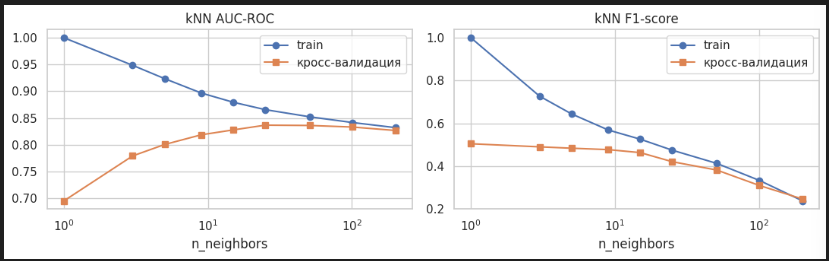

*Рис.13.Подбор гиперпараметров kNN: n_neighbors и p (метрика Минковского)*

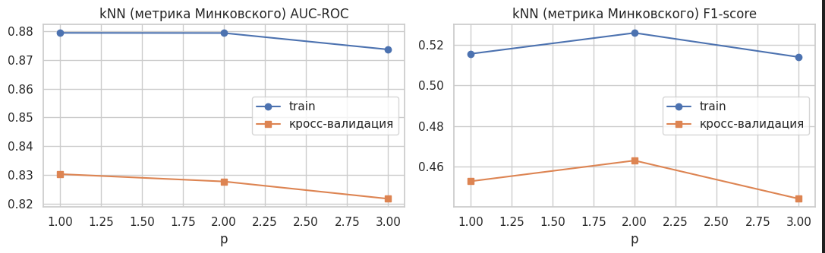

*Рис.14.Настройка kNN: зависимость метрик от n_neighbors и параметра p*

**Результат.**

- **Число соседей.** При k = 1 модель идеально описывает train (AUC 1.000), но на кросс-валидации AUC всего 0.695 — каждый прогноз определяется одним случайным соседом. С ростом k кривые сходятся, AUC на валидации достигает максимума **0.837 при k = 25** и затем медленно снижается (0.827 при k = 201): слишком большая окрестность «размывает» локальную структуру.
- **F1 при пороге по умолчанию** падает с ростом k (0.504 при k = 1 → 0.246 при k = 201): в большой окрестности почти всегда преобладают обычные вина (их ≈ 81 %), и голосование их и выбирает. Порог по умолчанию придётся сдвигать.
- **Метрика.** Манхэттенская (p = 1: AUC 0.830) и евклидова (p = 2: 0.828) практически не отличаются, p = 3 немного хуже (0.822).
- **GridSearchCV:** лучшее — `{'n_neighbors': 51, 'p': 1, 'weights': 'distance'}`, CV AUC 0.8493. Веса `distance` (ближайшие соседи важнее дальних) в лучших вариантах лучше равных весов. Тестовый AUC вырос с 0.784 до 0.836.

**Что делает ячейка.** Сводит в одну таблицу F1 и AUC-ROC каждого метода до настройки (baseline) и после, причём F1 приведён в двух вариантах: после настройки при пороге по умолчанию и после подбора порога. Это позволяет разделить эффект гиперпараметров и эффект порога.

In [ ]:
cmp = pd.DataFrame({
    "F1 baseline": pd.DataFrame(RESULTS_BASE).T["F1"],
    "F1 tuned, порог по умолч.": pd.DataFrame(RESULTS_TUNED_DEF).T["F1"],
    "F1 tuned, порог подобран": pd.DataFrame(RESULTS_TUNED).T["F1"],
    "AUC baseline": pd.DataFrame(RESULTS_BASE).T["AUC-ROC"],
    "AUC tuned": pd.DataFrame(RESULTS_TUNED).T["AUC-ROC"],
    "порог": pd.Series(THRESHOLDS),
}).round(4)
print("Таблица 12. Сравнение F1 и AUC-ROC: baseline vs настройка vs подбор порога")
cmp

,F1 baseline,"F1 tuned, порог по умолч.","F1 tuned, порог подобран",AUC baseline,AUC tuned,порог
GaussianNB,0.4750,0.0000,0.4719,0.7499,0.7652,0.2151
MultinomialNB,0.0000,0.0000,0.4895,0.7566,0.7836,0.1946
ComplementNB,0.4610,0.3636,0.4912,0.7566,0.7922,0.5007
BernoulliNB,0.3957,0.4266,0.4710,0.7196,0.7490,0.3002
DecisionTree,0.4105,0.4878,0.5108,0.6371,0.7885,0.5738
LDA,0.4251,0.4251,0.5180,0.8152,0.8152,0.2054
SVM,0.4070,0.5320,0.5430,0.8108,0.8359,0.4189
kNN,0.4451,0.4415,0.5191,0.7838,0.8355,0.2807


**Результат.**

- **AUC-ROC вырос почти у всех методов.** Больше всего — у дерева решений (0.637 → 0.788, **+0.151**) и kNN (0.784 → 0.836, +0.052): модели, которые по умолчанию переобучаются, выигрывают от ограничения сложности. У SVM +0.025, у наивных байесовских +0.015…+0.036; у LDA изменений нет.
- **F1 при пороге по умолчанию у ряда моделей упал:** GaussianNB 0.475 → 0.000, ComplementNB 0.461 → 0.364. Причина в том, что параметры подбирались по ROC-AUC, который не зависит от порога: ранжирование стало лучше, а порог 0,5 остался неудачным.
- **Подбор порога решает проблему:** после него F1 у всех моделей лежит в диапазоне 0.47–0.54, причём лучший — SVM (0.543). Подобранные пороги (0.19–0.57) заметно ниже 0,5 — модель должна «охотнее» объявлять вино хорошим из-за дисбаланса классов.

**Что делает ячейка.** Рисует то же сравнение в виде диаграмм: AUC-ROC и F1 каждого метода до и после настройки.

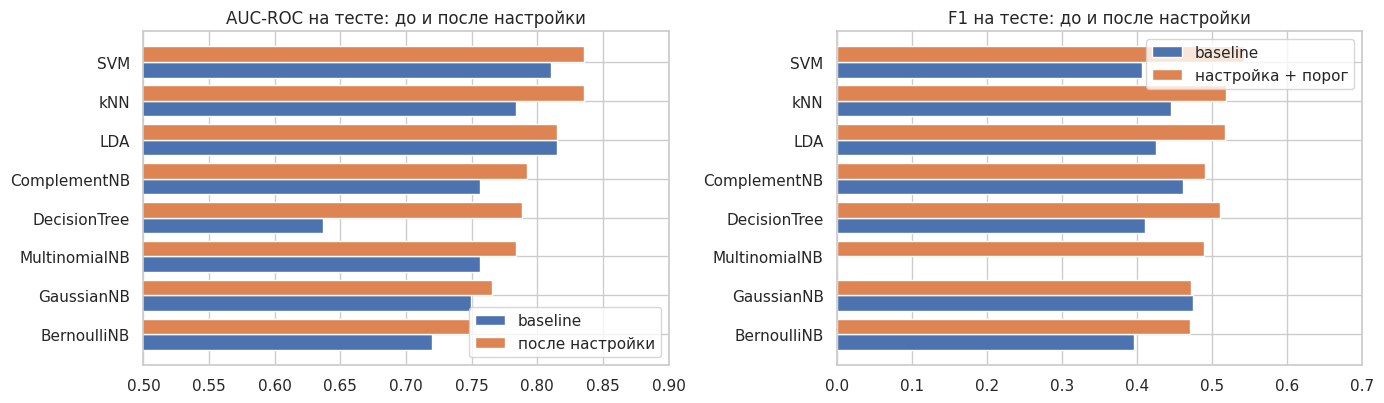

In [ ]:
print("Рисунок 4. Сравнение AUC-ROC и F1 на тесте: baseline vs после настройки гиперпараметров")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
order = pd.DataFrame(RESULTS_TUNED).T["AUC-ROC"].sort_values().index
y_pos = np.arange(len(order))
ax[0].barh(y_pos - 0.2, pd.DataFrame(RESULTS_BASE).T.loc[order, "AUC-ROC"], 0.4, label="baseline")
ax[0].barh(y_pos + 0.2, pd.DataFrame(RESULTS_TUNED).T.loc[order, "AUC-ROC"], 0.4, label="после настройки")
ax[0].set_yticks(y_pos); ax[0].set_yticklabels(order); ax[0].set_xlim(0.5, 0.9)
ax[0].set_title("AUC-ROC на тесте: до и после настройки"); ax[0].legend()
ax[1].barh(y_pos - 0.2, pd.DataFrame(RESULTS_BASE).T.loc[order, "F1"], 0.4, label="baseline")
ax[1].barh(y_pos + 0.2, pd.DataFrame(RESULTS_TUNED).T.loc[order, "F1"], 0.4, label="настройка + порог")
ax[1].set_yticks(y_pos); ax[1].set_yticklabels(order); ax[1].set_xlim(0, 0.7)
ax[1].set_title("F1 на тесте: до и после настройки"); ax[1].legend()
plt.tight_layout(); plt.show()

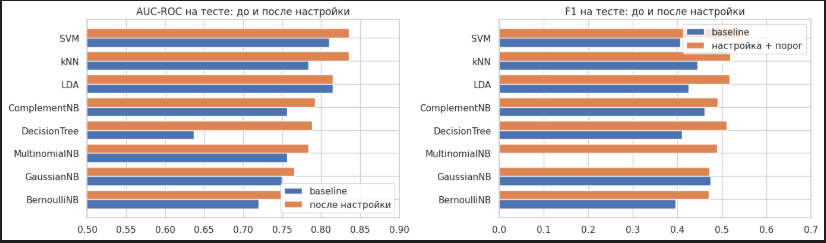

*Рис.15.Итоговое сравнение качества моделей (AUC-ROC и F1-score) до и после тюнинга*

## 6. Нейронная сеть на TensorFlow

**Архитектура (базовая):** полносвязная сеть (MLP) `Input(12) → Dense(64, ReLU) → Dropout(0.2) → Dense(32, ReLU) → Dropout(0.2) → Dense(1, sigmoid)`.

* **Функция потерь:** `binary_crossentropy` (бинарная классификация, на выходе вероятность класса 1).
* **Оптимизатор:** Adam (`lr = 1e-3`).
* **Метрики:** accuracy, AUC.
* **Регуляризация:** Dropout и `EarlyStopping` по `val_loss` (с возвратом лучших весов).
* **Данные:** те же признаки (со `StandardScaler`), что у классических методов. 20 % обучающей выборки стратифицированно выделяются под **валидацию**; тест в обучении и выборе модели не участвует.
* **TensorBoard:** каждый эксперимент пишет логи в `logs/<имя>` через `keras.callbacks.TensorBoard` (loss, accuracy, AUC на обучении и валидации).

Исследуется влияние: размера батча и числа эпох, числа слоёв и нейронов, функции активации, скорости обучения, Dropout и весов классов. **Лучшая конфигурация выбирается по AUC на валидации**, порог классификации подбирается по F1 на валидации (так же, как у классических методов — по обучающим данным).

> **Важно.** Раздел 6 требует установленного TensorFlow. Результаты, графики и пояснения ниже формируются при выполнении ячеек (выводы пересчитываются автоматически), поэтому у ячеек этого раздела вывод появится после запуска. Обучение небольшое (около 3 400 объектов) и занимает несколько минут на CPU. Из-за особенностей TensorFlow числа могут слегка отличаться между запусками и компьютерами, несмотря на фиксацию seed.

**Что делает ячейка.** Подготавливает и обучает базовую **нейронную сеть**.

- Фиксируются seed для Python, NumPy и TensorFlow; очищается папка `logs`.
- Берутся те же стандартизованные признаки, что у классических методов; из train выделяется стратифицированная валидация (20 %).
- `build_model()` строит полносвязную сеть: `n_layers` скрытых слоёв (число нейронов уменьшается вдвое от слоя к слою, 64 → 32), после каждого — Dropout, на выходе один нейрон с sigmoid. Потери — бинарная кросс-энтропия, оптимизатор — Adam, метрики — accuracy и AUC.
- `run_nn()` обучает сеть с колбэками `TensorBoard` и `EarlyStopping` (терпение 8 эпох, возврат лучших весов), подбирает порог по F1 на валидации и считает метрики на тесте и время обучения.
- `plot_hist()` рисует кривые loss, accuracy и AUC (сплошная — валидация, пунктир — обучение); `nn_table()` собирает таблицу результатов.
- `base_model.summary()` выводит архитектуру и число параметров.

In [ ]:
import datetime, shutil
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# ---------- воспроизводимость ----------
os.environ["PYTHONHASHSEED"] = str(SEED)
tf.random.set_seed(SEED)
keras.utils.set_random_seed(SEED)

# ---------- данные: те же признаки (StandardScaler), что и у классических методов ----------
Xtrain_all, Xte_nn = DATA["std"]
# из обучающей выборки выделяем стратифицированную валидацию (20%); тест не трогаем
Xtr_nn, Xval_nn, ytr_nn, yval_nn = train_test_split(
    Xtrain_all, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
ytr_nn, yval_nn = ytr_nn.astype("float32"), yval_nn.astype("float32")
print("обучение:", Xtr_nn.shape, " валидация:", Xval_nn.shape, " тест:", Xte_nn.shape)

LOG_ROOT = Path("logs")                 # сюда пишет TensorBoard
shutil.rmtree(LOG_ROOT, ignore_errors=True)


def build_model(n_layers=2, units=64, activation="relu", lr=1e-3, dropout=0.2):
    keras.utils.set_random_seed(SEED)
    m = keras.Sequential([layers.Input(shape=(Xtr_nn.shape[1],))])
    for i in range(n_layers):
        m.add(layers.Dense(max(units // (2 ** i), 8), activation=activation))
        if dropout:
            m.add(layers.Dropout(dropout))
    m.add(layers.Dense(1, activation="sigmoid"))
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="binary_crossentropy",
              metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return m


def pick_threshold(y_true, prob):
    # порог, максимизирующий F1, подбирается на ВАЛИДАЦИОННЫХ предсказаниях
    cands = np.unique(np.quantile(prob, np.linspace(0.02, 0.98, 97)))
    f1s = [f1_score(y_true, prob >= t) for t in cands]
    return float(cands[int(np.argmax(f1s))])


NN_RES, NN_HIST = {}, {}


def run_nn(name, epochs=60, batch_size=32, patience=8, class_weight=None, **kw):
    # patience=None отключает раннюю остановку (нужно для эксперимента с числом эпох)
    m = build_model(**kw)
    cbs = [keras.callbacks.TensorBoard(log_dir=str(LOG_ROOT / name))]
    if patience is not None:
        cbs.append(keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.time()
    h = m.fit(Xtr_nn, ytr_nn, validation_data=(Xval_nn, yval_nn),
              epochs=epochs, batch_size=batch_size, class_weight=class_weight,
              callbacks=cbs, verbose=0)
    val_prob = m.predict(Xval_nn, verbose=0).ravel()
    prob = m.predict(Xte_nn, verbose=0).ravel()
    thr = pick_threshold(yval_nn, val_prob)
    res = metrics_from(y_test, prob >= thr, prob)
    NN_RES[name] = {"val AUC": roc_auc_score(yval_nn, val_prob), **res,
                    "порог": thr, "эпох": len(h.history["loss"]), "время, с": time.time() - t0}
    NN_HIST[name] = (h.history, prob)
    return m


def plot_hist(names, caption=None):
    if caption:
        print(caption)
    fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
    for n in names:
        h = NN_HIST[n][0]
        for a, (tr, va) in zip(ax, [("loss", "val_loss"), ("accuracy", "val_accuracy"), ("auc", "val_auc")]):
            line, = a.plot(h[va], label=n)
            a.plot(h[tr], "--", color=line.get_color(), alpha=.5)
    for a, t in zip(ax, ["Loss", "Accuracy", "AUC"]):
        a.set_title(f"{t} (сплошная — валидация, пунктир — обучение)", fontsize=9)
        a.set_xlabel("эпоха"); a.legend(fontsize=8)
    plt.tight_layout(); plt.show()


def nn_table(names):
    return pd.DataFrame({n: NN_RES[n] for n in names}).T.round(4)


# ---------- базовая модель ----------
base_model = run_nn("base")
base_model.summary()
plot_hist(["base"], caption="Рисунок 5. Кривые обучения базовой нейронной сети")
print("Таблица 13. Базовая нейронная сеть: метрики на валидации и тесте")
nn_table(["base"])

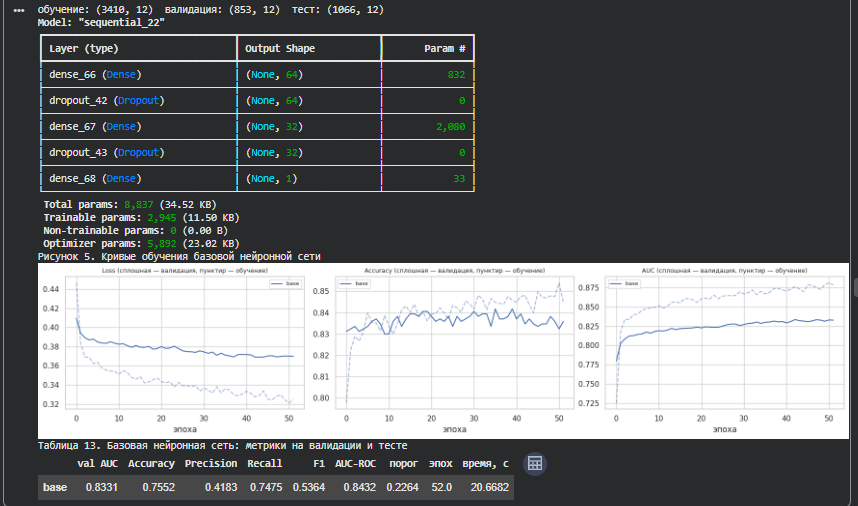

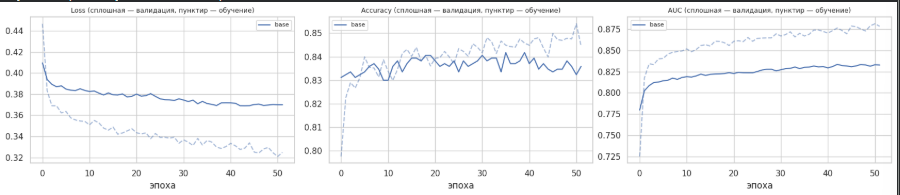

*Рис.16.кревые обучение базовой неросетейвой сети*

### 6.1 Размер батча и число эпох

**Что делает ячейка.** Эксперимент с **размером батча** (16, 32, 64, 128, 256 объектов на шаг градиентного спуска). Чем меньше батч, тем больше шагов за эпоху и «шумнее» градиент. Для каждого значения строятся кривые обучения и выводится таблица (`val AUC` — AUC на валидации по лучшим весам, остальные метрики — на тесте).

In [ ]:
batches = [16, 32, 64, 128, 256]
for bs in batches:
    if bs != 32:
        run_nn(f"batch_{bs}", batch_size=bs)
NN_HIST["batch_32"], NN_RES["batch_32"] = NN_HIST["base"], NN_RES["base"]
plot_hist([f"batch_{b}" for b in batches], caption="Рисунок 6. Кривые обучения: влияние размера батча")
print("Таблица 14. Нейросеть: влияние размера батча")
nn_table([f"batch_{b}" for b in batches])

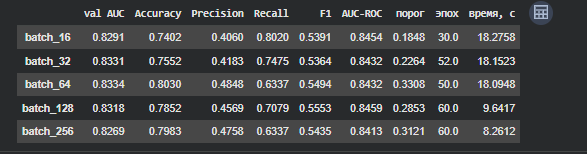

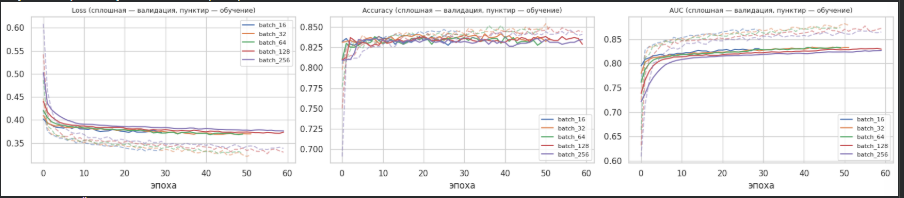


*Рис.17.Кривые обучения: влияние размера батча*

**Что делает ячейка.** Эксперимент с **числом эпох** (5, 20, 60, 120) **без ранней остановки** (`patience=None`): видно, как качество зависит от длительности обучения — недообучение при малом числе эпох и переобучение при большом (расхождение train/validation на графиках loss и AUC).

In [ ]:
epoch_list = [5, 20, 60, 120]
for ep in epoch_list:
    run_nn(f"epochs_{ep}", epochs=ep, patience=None)      # без ранней остановки
plot_hist([f"epochs_{e}" for e in epoch_list], caption="Рисунок 7. Кривые обучения: влияние числа эпох")
print("Таблица 15. Нейросеть: влияние числа эпох (без ранней остановки)")
nn_table([f"epochs_{e}" for e in epoch_list])

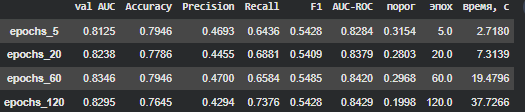

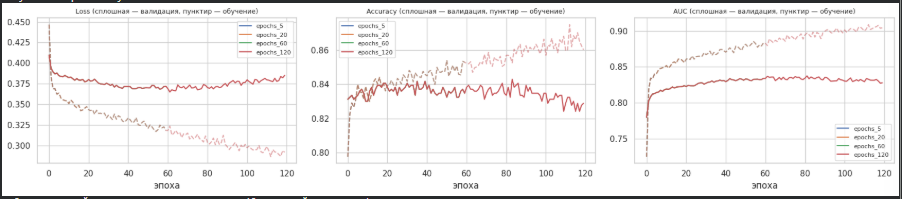

*Рис.18.Кривые обучения: влияние числа эпох*

### 6.2 Количество слоёв и нейронов

**Что делает ячейка.** Исследует **архитектуру**: число скрытых слоёв (1–3) и нейронов в первом слое (16, 64, 128); в следующих слоях число нейронов уменьшается вдвое. Например, `L3_U128` — три слоя 128 → 64 → 32.

In [ ]:
archs = [(1, 16), (1, 64), (2, 64), (3, 64), (3, 128)]
for L, U in archs:
    if (L, U) != (2, 64):
        run_nn(f"L{L}_U{U}", n_layers=L, units=U)
NN_HIST["L2_U64"], NN_RES["L2_U64"] = NN_HIST["base"], NN_RES["base"]
plot_hist([f"L{L}_U{U}" for L, U in archs], caption="Рисунок 8. Кривые обучения: влияние архитектуры сети")
print("Таблица 16. Нейросеть: влияние архитектуры (число слоёв и нейронов)")
nn_table([f"L{L}_U{U}" for L, U in archs])

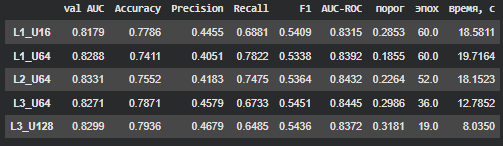

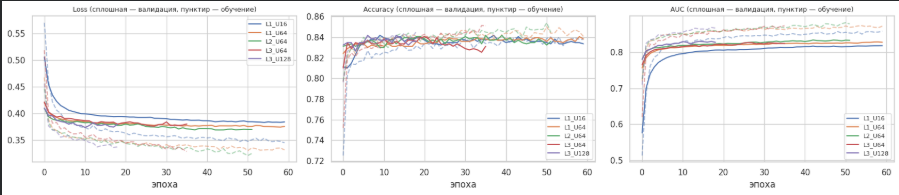

*Рис.19.Кривые обучения: влияние архитектуры сети*

### 6.3 Функции активации, скорость обучения, Dropout и веса классов

**Что делает ячейка.** Исследует **функции активации** скрытых слоёв (ReLU, tanh, sigmoid, ELU, linear).

In [ ]:
acts = ["relu", "tanh", "sigmoid", "elu", "linear"]
for a in acts:
    if a != "relu":
        run_nn(f"act_{a}", activation=a)
NN_HIST["act_relu"], NN_RES["act_relu"] = NN_HIST["base"], NN_RES["base"]
plot_hist([f"act_{a}" for a in acts], caption="Рисунок 9. Кривые обучения: влияние функции активации")
print("Таблица 17. Нейросеть: влияние функции активации")
nn_table([f"act_{a}" for a in acts])

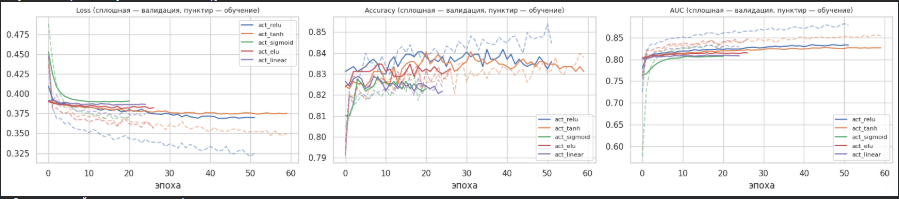

*Рис.20.Кривые обучения: влияние функции активации*


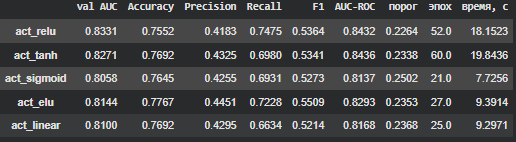      


**Что делает ячейка.** Исследует **скорость обучения** Adam (10⁻⁴, 10⁻³, 10⁻²), **Dropout** (0, 0,2, 0,5) и **веса классов** (`class_weight`: редкий класс получает вес ≈ 4, обратный его доле).

In [ ]:
for lr in [1e-4, 1e-2]:
    run_nn(f"lr_{lr}", lr=lr)
NN_HIST["lr_0.001"], NN_RES["lr_0.001"] = NN_HIST["base"], NN_RES["base"]
for dr in [0.0, 0.5]:
    run_nn(f"drop_{dr}", dropout=dr)
NN_HIST["drop_0.2"], NN_RES["drop_0.2"] = NN_HIST["base"], NN_RES["base"]
# учёт дисбаланса классов: вес редкого класса выше
w1 = (1 - y_train.mean()) / y_train.mean()
run_nn("class_weight", class_weight={0: 1.0, 1: float(w1)})
plot_hist(["lr_0.0001", "lr_0.001", "lr_0.01"], caption="Рисунок 10. Кривые обучения: влияние скорости обучения")
plot_hist(["drop_0.0", "drop_0.2", "drop_0.5", "class_weight"], caption="Рисунок 11. Кривые обучения: Dropout и веса классов")
print("Таблица 18. Нейросеть: скорость обучения, Dropout и веса классов")
nn_table(["lr_0.0001", "lr_0.001", "lr_0.01", "drop_0.0", "drop_0.2", "drop_0.5", "class_weight"])

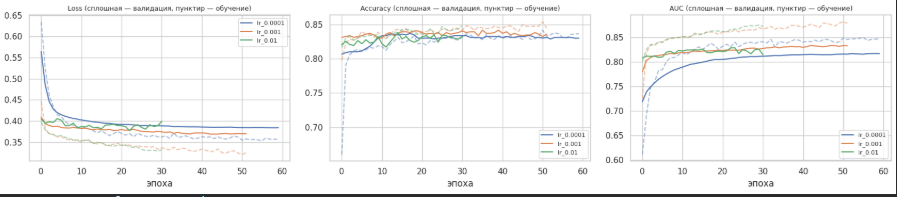

*Рис.21.Кривые обучения: влияние скорости обучения*


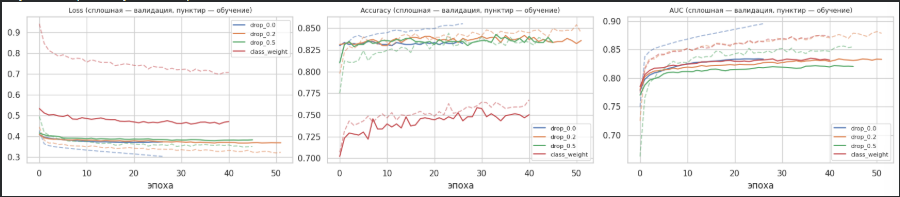


*Рис.22.Кривые обучения: Dropout и веса классов*


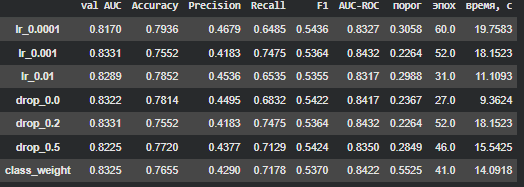

### 6.4 Мониторинг в TensorBoard

**Что делает ячейка.** Запускает **TensorBoard** прямо в ноутбуке: `%load_ext` загружает расширение, `%tensorboard --logdir logs` поднимает сервер и встраивает интерфейс в ячейку. На вкладке *Scalars* для каждого эксперимента (папка `logs/<имя>`) доступны кривые `epoch_loss`, `epoch_accuracy`, `epoch_auc` для обучения и валидации (`validation`), все эксперименты можно сравнивать на одном графике. Из терминала: `tensorboard --logdir logs`, затем открыть http://localhost:6006.

Встроенная панель отображается только в работающем Jupyter/Colab; в сохранённом файле и при просмотре на GitHub она пустая.

In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs

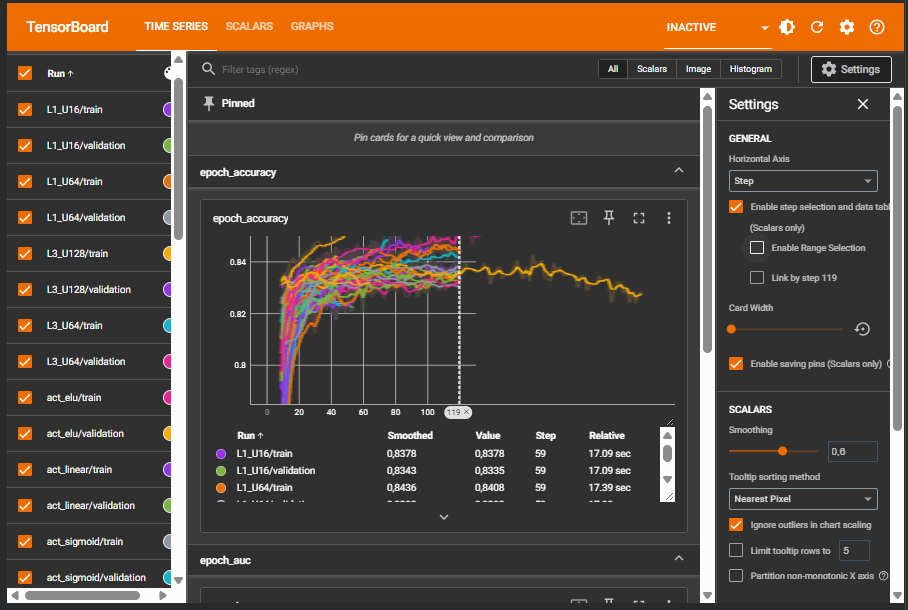

**Что делает ячейка.** Выводит краткий автоматический разбор экспериментов: для каждой группы (батч, эпохи, архитектура, активация, скорость обучения, dropout) — лучшая и худшая конфигурации по валидационному AUC и разброс между ними. Разброс помогает понять, какие гиперпараметры действительно важны, а какие почти не влияют.

In [ ]:
# краткий автоматический разбор экспериментов с нейросетью
groups = {
    "размер батча":   [f"batch_{b}" for b in batches],
    "число эпох":     [f"epochs_{e}" for e in epoch_list],
    "архитектура":    [f"L{L}_U{U}" for L, U in archs],
    "активация":      [f"act_{a}" for a in acts],
    "скорость обуч.": ["lr_0.0001", "lr_0.001", "lr_0.01"],
    "dropout":        ["drop_0.0", "drop_0.2", "drop_0.5"],
}
for title, names in groups.items():
    t = pd.DataFrame({n: NN_RES[n] for n in names}).T
    b, w = t["val AUC"].idxmax(), t["val AUC"].idxmin()
    print(f"{title:>15}: лучший {b} (val AUC {t.loc[b, 'val AUC']:.4f}, test F1 {t.loc[b, 'F1']:.4f}, эпох {int(t.loc[b, 'эпох'])}); "
          f"худший {w} (val AUC {t.loc[w, 'val AUC']:.4f}); разброс val AUC = {t['val AUC'].max() - t['val AUC'].min():.4f}")

размер батча: лучший batch_64 (val AUC 0.8334, test F1 0.5494, эпох 50); худший batch_256 (val AUC 0.8269); разброс val AUC = 0.0066

число эпох: лучший epochs_60 (val AUC 0.8346, test F1 0.5485, эпох 60); худший epochs_5 (val AUC 0.8125); разброс val AUC = 0.0220

архитектура: лучший L2_U64 (val AUC 0.8331, test F1 0.5364, эпох 52); худший L1_U16 (val AUC 0.8179); разброс val AUC = 0.0151

активация: лучший act_relu (val AUC 0.8331, test F1 0.5364, эпох 52); худший act_sigmoid (val AUC 0.8058); разброс val AUC = 0.0272

скорость обуч.: лучший lr_0.001 (val AUC 0.8331, test F1 0.5364, эпох 52); худший lr_0.0001 (val AUC 0.8170); разброс val AUC = 0.0161

dropout: лучший drop_0.2 (val AUC 0.8331, test F1 0.5364, эпох 52); худший drop_0.5 (val AUC 0.8225); разброс val AUC = 0.0106


**Что делает ячейка.** Выбирает лучшую конфигурацию нейросети по **валидационному** AUC-ROC (не по тесту), добавляет её тестовые метрики и ROC-кривую в итоговые результаты (`RESULTS_TUNED`, `ROC_TUNED`) и выводит топ-8 конфигураций.

In [ ]:
# лучшая конфигурация выбирается по ВАЛИДАЦИОННОМУ AUC (тест в выборе не участвует)
all_nn = pd.DataFrame(NN_RES).T.drop_duplicates(subset=["val AUC", "эпох"])
best_nn = all_nn["val AUC"].astype(float).idxmax()
print("Лучшая конфигурация нейросети по val AUC:", best_nn)
RESULTS_TUNED["NeuralNet"] = {k: NN_RES[best_nn][k] for k in ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]}
fpr, tpr, _ = roc_curve(y_test, NN_HIST[best_nn][1])
ROC_TUNED["NeuralNet"] = (fpr, tpr, NN_RES[best_nn]["AUC-ROC"])
TEST_SCORES["NeuralNet"] = NN_HIST[best_nn][1]
print("Таблица 19. Топ-8 конфигураций нейросети по валидационному AUC-ROC")
all_nn.sort_values("val AUC", ascending=False).head(8).round(4)

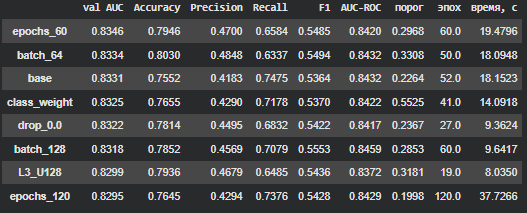

## 7. Сравнительный анализ

Итоговая таблица (настроенные модели, тестовая выборка), столбчатые диаграммы по метрикам, ROC-кривые и доверительные интервалы AUC. Для классических методов Accuracy, Precision, Recall и F1 приведены **при подобранном пороге**, AUC-ROC от порога не зависит.

> **Замечание.** Сохранённые ниже результаты получены для восьми классических моделей. Нейросеть (раздел 6) добавляется в эти таблицы и графики автоматически, если выполнить раздел 6 до этих ячеек (или перезапустить их после него).

**Что делает ячейка.** Собирает итоговую таблицу метрик всех настроенных моделей на тестовой выборке, сортирует по AUC-ROC и сохраняет её в `final_metrics.csv`.

In [ ]:
final = pd.DataFrame(RESULTS_TUNED).T.round(4).sort_values("AUC-ROC", ascending=False)
final.to_csv("final_metrics.csv")
print("Таблица 20. Итоговые метрики всех настроенных моделей на тестовой выборке")
final

,Accuracy,Precision,Recall,F1,AUC-ROC
SVM,0.7805,0.4484,0.6881,0.5430,0.8359
kNN,0.7636,0.4224,0.6733,0.5191,0.8355
LDA,0.7486,0.4068,0.7129,0.5180,0.8152
ComplementNB,0.6754,0.3494,0.8267,0.4912,0.7922
DecisionTree,0.7448,0.4011,0.7030,0.5108,0.7885
MultinomialNB,0.7495,0.3988,0.6337,0.4895,0.7836
GaussianNB,0.7270,0.3725,0.6436,0.4719,0.7652
BernoulliNB,0.7430,0.3861,0.6040,0.4710,0.7490


**Результат.**

- **По AUC-ROC** лидируют **SVM (0.836)** и **kNN (0.836)**, затем LDA (0.815); замыкают список GaussianNB (0.765) и BernoulliNB (0.749).
- **По F1** лучшая — SVM (0.543), за ней kNN (0.519). **Recall** максимален у ComplementNB (0.827), **Precision** — у SVM (0.448).
- **Accuracy** лежит в диапазоне 0.68–0.78 и при подобранном пороге ниже, чем у «всегда отвечающей 0» модели (0.811): это плата за обнаружение редкого класса — Recall около 0.68. Именно поэтому accuracy здесь не показатель качества.
- Выигрыш по AUC даёт **нелинейность и локальность**: SVM с RBF-ядром и kNN лучше наивного Байеса, который предполагает независимость признаков (а признаки здесь коррелируют, например плотность и спирт), и немного лучше LDA с линейной границей (различие с LDA статистически не значимо — см. ниже).

**Что делает ячейка.** Строит столбчатые диаграммы по каждой метрике (Accuracy, Precision, Recall, F1, AUC-ROC) и ROC-кривые всех моделей на одном графике.

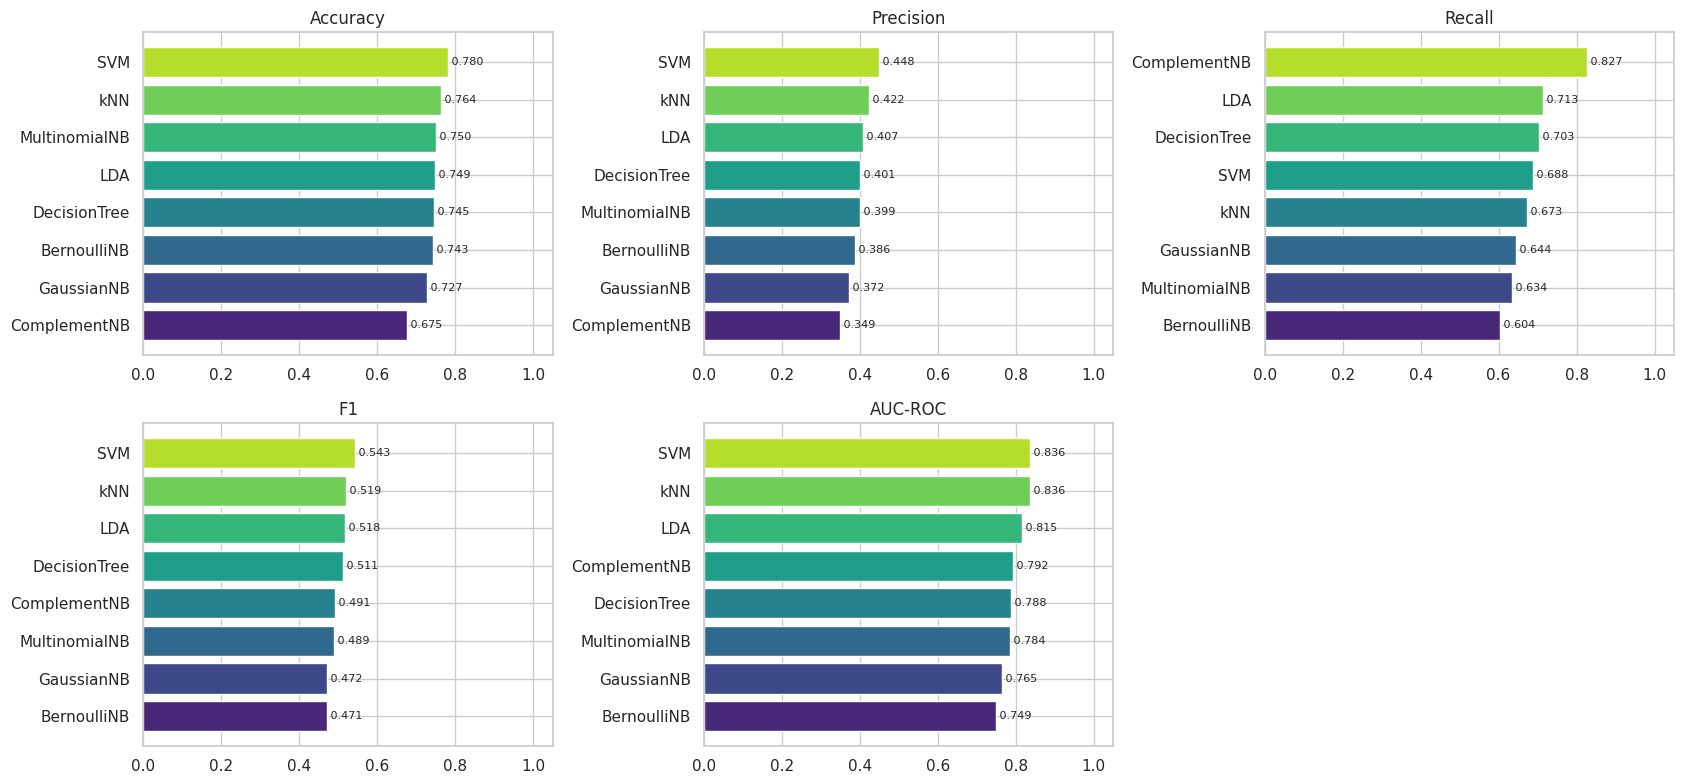

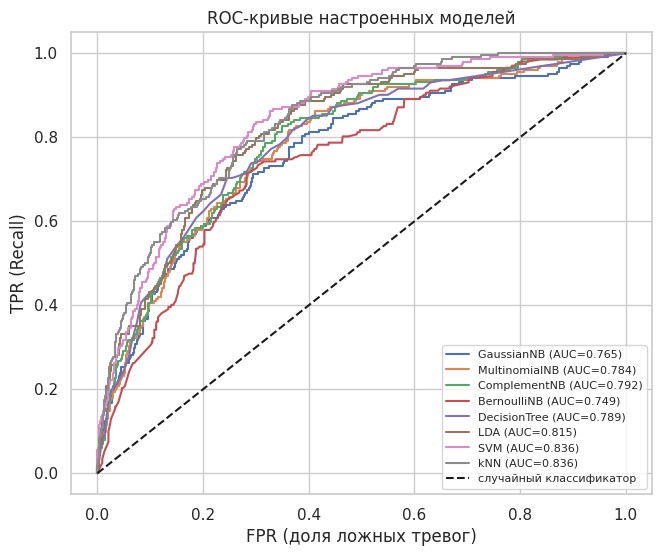

In [ ]:
print("Рисунок 12. Сравнение моделей по метрикам на тестовой выборке")
metrics = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]
fig, axes = plt.subplots(2, 3, figsize=(17, 8)); axes = axes.ravel()
for a, mt in zip(axes, metrics):
    s = final[mt].sort_values()
    a.barh(s.index, s.values, color=sns.color_palette("viridis", len(s)))
    for i, v in enumerate(s.values):
        a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
    a.set_title(mt); a.set_xlim(0, 1.05)
axes[-1].axis("off")
plt.tight_layout(); plt.show()

print("Рисунок 13. ROC-кривые настроенных моделей на тестовой выборке")
plt.figure(figsize=(7.5, 6))
for n, (f, t, auc) in ROC_TUNED.items():
    plt.plot(f, t, label=f"{n} (AUC={auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR (доля ложных тревог)"); plt.ylabel("TPR (Recall)")
plt.title("ROC-кривые настроенных моделей"); plt.legend(fontsize=8); plt.show()

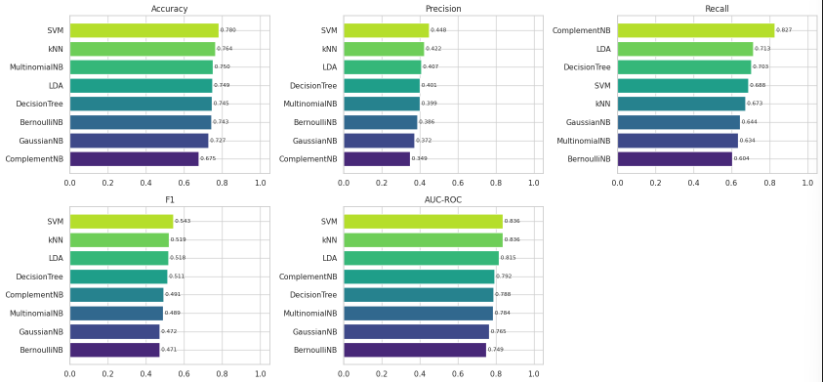

*Рис.23.Сравнение моделей классификации по метрикам качествa*

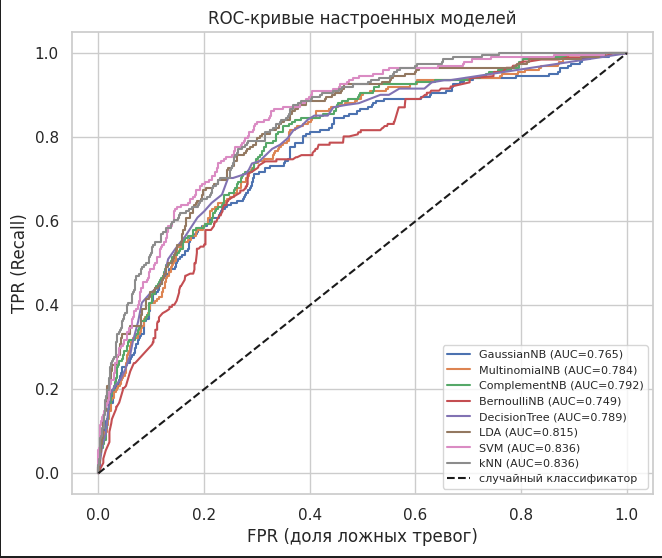

*Рис.24.Сравнение ROC-кривых и AUC всех обученных классификаторов*

**Результат.**

- **Accuracy** различает модели слабо (разница между лучшей и худшей 0.11), а **Recall и F1** — сильнее: Recall меняется от 0.60 до 0.83.
- **ROC-кривые** всех моделей лежат заметно выше диагонали и идут тесным пучком. SVM и kNN выше остальных в области малых и средних долей ложных тревог (FPR до ≈ 0,5), где обычно и выбирается рабочая точка; при больших FPR кривые переплетаются. BernoulliNB — самая нижняя в средней части.
- Кривые SVM и kNN практически сливаются — различие между ними меньше разброса, вызванного ограниченным размером теста (оценим ниже).

**Что делает ячейка.** Оценивает неопределённость AUC на тесте: 500 раз формирует bootstrap-выборку из тестовых объектов (с возвращением) и считает AUC каждой модели; выводит 95 %-й интервал (2,5-й и 97,5-й процентили) и рисует его на графике. Если интервалы двух моделей сильно перекрываются, различие между ними нельзя считать надёжным.

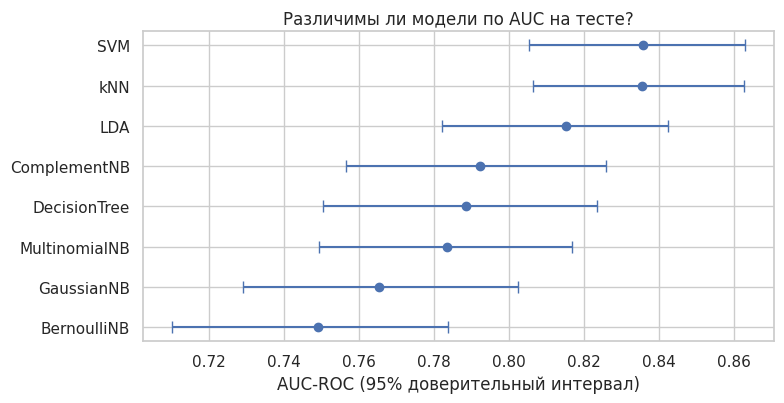

,AUC-ROC,2.5%,97.5%
SVM,0.8359,0.8054,0.8631
kNN,0.8355,0.8065,0.8627
LDA,0.8152,0.7821,0.8426
ComplementNB,0.7922,0.7565,0.8259
DecisionTree,0.7885,0.7503,0.8236
MultinomialNB,0.7836,0.7493,0.8169
GaussianNB,0.7652,0.7289,0.8024
BernoulliNB,0.7490,0.7101,0.7837


In [ ]:
# 95% доверительные интервалы AUC на тесте (bootstrap по тестовым объектам, 500 повторов)
rng = np.random.RandomState(SEED)
boot_idx = [rng.randint(0, len(y_test), len(y_test)) for _ in range(500)]
rows = {}
for name, sc in TEST_SCORES.items():
    aucs = [roc_auc_score(y_test[i], sc[i]) for i in boot_idx]
    rows[name] = {"AUC-ROC": roc_auc_score(y_test, sc),
                  "2.5%": np.percentile(aucs, 2.5), "97.5%": np.percentile(aucs, 97.5)}
ci = pd.DataFrame(rows).T.sort_values("AUC-ROC", ascending=False)

print("Рисунок 14. 95%-е доверительные интервалы AUC-ROC на тесте (bootstrap)")
plt.figure(figsize=(8, 4.2))
yy = np.arange(len(ci))[::-1]
plt.errorbar(ci["AUC-ROC"], yy, xerr=[ci["AUC-ROC"] - ci["2.5%"], ci["97.5%"] - ci["AUC-ROC"]],
             fmt="o", capsize=4)
plt.yticks(yy, ci.index); plt.xlabel("AUC-ROC (95% доверительный интервал)")
plt.title("Различимы ли модели по AUC на тесте?"); plt.tight_layout(); plt.show()
print("Таблица 21. 95%-е доверительные интервалы AUC-ROC на тесте (bootstrap, 500 повторов)")
ci.round(4)

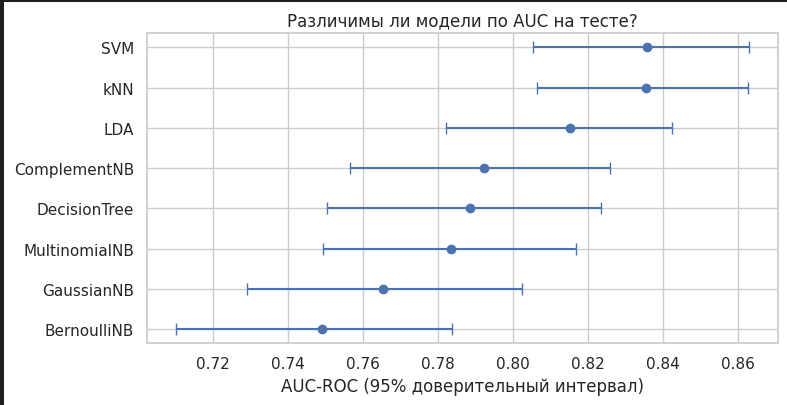

*Рис.25.Сравнение AUC-ROC моделей с 95% доверительными интервалами*

**Результат.** Ширина 95 %-го интервала AUC около 0.066 (≈ ±0.033): в тесте всего ≈ 202 хороших вин. Интервал лучшей модели (SVM, 0.836) **пересекается** с интервалами моделей kNN, LDA, ComplementNB, DecisionTree, MultinomialNB — их различие с лучшей по AUC нельзя считать надёжным (сравнение по пересечению интервалов консервативно, но показывает порядок неопределённости). **Не пересекаются** с лучшей модели GaussianNB, BernoulliNB: они статистически хуже. Практический вывод: SVM и kNN лидируют, но между собой, а также с LDA их качество по AUC неразличимо; уверенно хуже лидеров лишь GaussianNB, BernoulliNB.

**Что делает ячейка.** Выводит модели с наибольшим AUC-ROC и наибольшим F1, список моделей, статистически неотличимых от лучшей по AUC, и (если выполнен раздел 6) место нейросети.

In [ ]:
best_auc, best_f1 = final["AUC-ROC"].idxmax(), final["F1"].idxmax()
print(f"Наибольший AUC-ROC: {best_auc} ({final.loc[best_auc, 'AUC-ROC']:.4f})")
print(f"Наибольший F1:      {best_f1} ({final.loc[best_f1, 'F1']:.4f})")
print("Модели, чей 95% интервал AUC пересекается с интервалом лучшей:",
      [n for n in ci.index if ci.loc[n, "97.5%"] >= ci.loc[best_auc, "2.5%"] and ci.loc[best_auc, "97.5%"] >= ci.loc[n, "2.5%"] and n != best_auc])
if "NeuralNet" in final.index:
    rank = list(final.index).index("NeuralNet") + 1
    print(f"Нейросеть: AUC = {final.loc['NeuralNet', 'AUC-ROC']:.4f}, F1 = {final.loc['NeuralNet', 'F1']:.4f}, место по AUC: {rank} из {len(final)}")
else:
    print("Нейросеть в сравнение не включена: сначала выполните раздел 6.")

Наибольший AUC-ROC: SVM (0.8359)
Наибольший F1:      SVM (0.5430)
Модели, чей 95% интервал AUC пересекается с интервалом лучшей: ['kNN', 'LDA', 'ComplementNB', 'DecisionTree', 'MultinomialNB']
Нейросеть в сравнение не включена: сначала выполните раздел 6.


**Вывод о лучшем подходе (для классических методов).**

- Сравнивать методы нужно прежде всего по **AUC-ROC и F1**, а не по accuracy: при доле хороших вин 19 % модель «всегда обычное вино» уже даёт accuracy 0.81.
- **Лучший по всем основным метрикам — SVM с RBF-ядром** (`C = 1`, `gamma = "scale"`, `class_weight = "balanced"`): AUC-ROC 0.836, F1 0.543, наибольшая Precision и accuracy при хорошем Recall (0.69). Его недостатки — самое долгое обучение и настройка (десятки секунд против долей секунды у остальных) и отсутствие прямой интерпретируемости.
- **kNN** даёт практически тот же AUC (0.836) и F1 0.519; он проще, но хранит всю обучающую выборку и медленнее на предсказании.
- **LDA** (AUC 0.815, F1 0.518) не требует настройки, мгновенно обучается и интерпретируем (линейные коэффициенты); для практики это сильный компромисс.
- Из-за коррелированных признаков **наивный Байес** уступает: лучший из его вариантов — ComplementNB (0.792), худший — BernoulliNB (0.749).
- **Дерево решений** без ограничений бесполезно (AUC 0.637); после настройки глубины и размера листа оно достигает 0.788 и сохраняет главное достоинство — читаемые правила.
- Вывод о нейронной сети делается после выполнения раздела 6 (см. итоговую ячейку ниже): её нужно сравнивать с SVM и kNN с учётом доверительных интервалов.

**Что делает ячейка.** Формирует итоговый вывод, включающий нейросеть: сравнивает её AUC и F1 с лучшими классическими методами и проверяет, различимы ли они статистически (пересечение 95 %-х интервалов). Требует выполненных разделов 6 и 7 и выводит текст на основе реальных чисел текущего запуска.

In [ ]:
final = pd.DataFrame(RESULTS_TUNED).T.sort_values("AUC-ROC", ascending=False)
if "NeuralNet" not in final.index:
    print("Сначала выполните раздел 6 (нейронная сеть), затем перезапустите ячейки раздела 7.")
else:
    rng = np.random.RandomState(SEED)
    boot_idx = [rng.randint(0, len(y_test), len(y_test)) for _ in range(500)]
    ci = pd.DataFrame({n: {"AUC": roc_auc_score(y_test, sc),
                           "lo": np.percentile([roc_auc_score(y_test[i], sc[i]) for i in boot_idx], 2.5),
                           "hi": np.percentile([roc_auc_score(y_test[i], sc[i]) for i in boot_idx], 97.5)}
                       for n, sc in TEST_SCORES.items()}).T
    best_cl = final.drop(index="NeuralNet")["AUC-ROC"].idxmax()
    nn, bc = final.loc["NeuralNet"], final.loc[best_cl]
    overlap = ci.loc["NeuralNet", "lo"] <= ci.loc[best_cl, "hi"] and ci.loc[best_cl, "lo"] <= ci.loc["NeuralNet", "hi"]
    print(f"Лучшая конфигурация нейросети (по val AUC): {best_nn}")
    print(f"Нейросеть:  AUC-ROC = {nn['AUC-ROC']:.4f}, F1 = {nn['F1']:.4f}, Recall = {nn['Recall']:.4f}, Precision = {nn['Precision']:.4f}")
    print(f"{best_cl}: AUC-ROC = {bc['AUC-ROC']:.4f}, F1 = {bc['F1']:.4f} (лучший классический метод по AUC)")
    print(f"Разность AUC (нейросеть - {best_cl}) = {nn['AUC-ROC'] - bc['AUC-ROC']:+.4f}")
    print("95% интервалы AUC", "пересекаются: различие статистически не значимо." if overlap
          else "не пересекаются: различие статистически значимо.")
    place = list(final.index).index("NeuralNet") + 1
    print(f"Место нейросети по AUC-ROC: {place} из {len(final)}.")

## 8. Заключение

В работе решена задача бинарной классификации вин по качеству (класс 1 — оценка ≥ 7) на датасете Wine Quality: после удаления 1168 дубликатов осталось 5329 вин, 12 признаков после кодирования, доля хороших вин 19.0 %. Построены и сравнены четыре варианта наивного Байеса, дерево решений, LDA, SVM, kNN и нейронная сеть на TensorFlow.

**Данные и метрики.** Из-за дисбаланса классов (1 : 4) accuracy малоинформативна, поэтому сравнение проводилось по F1, Recall и AUC-ROC; разбиение стратифицированное, предобработка обучалась только на train. Важное наблюдение: дубликаты нужно удалять до разбиения, иначе копии одного вина попадают и в train, и в test.

**Гиперпараметры.** Сильнее всего на качество влияют параметры, отвечающие за сложность модели: глубина дерева и размер листа (AUC дерева вырос с 0.637 до 0.789), число соседей в kNN (0.784 → 0.836), `C` и `gamma` у SVM (0.811 → 0.836). Слишком сложные модели переобучались — это видно по расхождению кривых train и валидации. У LDA параметры по умолчанию оказались оптимальными; у наивного Байеса `alpha` и `var_smoothing` дают умеренный прирост AUC, но большие значения разрушают модель. Подбор по ROC-AUC улучшил ранжирование, но при пороге 0,5 у ряда моделей снизил F1; помог отдельный подбор порога классификации на обучающих данных (F1 всех моделей после этого — 0.47–0.54).

**Лучший классический метод.** SVM с RBF-ядром: AUC-ROC 0.836, F1 0.543. Однако на тесте из ≈ 202 хороших вин доверительный интервал AUC имеет ширину ≈ 0.07, поэтому SVM, kNN и LDA по AUC статистически не различимы (их интервалы пересекаются); выбор между ними определяется требованиями к скорости, интерпретируемости и простоте.

**Нейронная сеть.** Реализована полносвязная сеть на TensorFlow/Keras (слои Dense с ReLU, Dropout, выход с sigmoid, потери binary crossentropy, оптимизатор Adam), обучение пишется в TensorBoard. Исследовано влияние размера батча, числа эпох, числа слоёв и нейронов, функции активации, скорости обучения, Dropout и весов классов; лучшая конфигурация выбирается по AUC на валидации, а не по тесту. Количественные выводы по нейросети формируются автоматически итоговой ячейкой раздела 7 после выполнения раздела 6.

**Практический вывод.** Для данных такого типа (небольшая таблица с коррелированными числовыми признаками и дисбалансом классов) нелинейные методы на основе расстояний или ядер (SVM, kNN) дают лучшее ранжирование, а простая линейная модель (LDA) близка к ним по качеству и значительно проще. Улучшить результат можно подбором порога под конкретную стоимость ошибок (пропустить хорошее вино или принять обычное за хорошее), отбором признаков с учётом корреляции плотности, спирта и сахара, и ансамблями деревьев (случайный лес, градиентный бустинг), которые выходят за рамки данной работы.